<a href="https://colab.research.google.com/github/arturo-olvrs/DDPM-MNIST/blob/main/ModelosDifusi%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Implementación de un DDPM (Denoising Diffusion Probabilistic Model) para el dataset MNIST

En este notebook implementaremos un DDPM básico en PyTorch, que emplearemos para generar dígitos de MNIST.

In [1]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import io
from PIL import Image
from IPython.display import display, Image as IPImage

SEED=42
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")

Dispositivo: cuda


In [2]:
import os
from google.colab import drive

drive.mount('/content/drive')

DRIVE_DIR = "/content/drive/MyDrive/modelos_difusion"
os.makedirs(DRIVE_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Para visualizar las imágenes, se puede emplear la escala de colores deseada, que se controla con la variable `CMAP` en la siguiente celda de código. Algunas de las opciones más utilizadas en Matplotlib son:

* **`viridis`**: Mapa de colores por defecto, secuencial y perceptualmente uniforme (tonos de azul, verde y amarillo).
* **`gray`**: Escala de grises clásica.
* **`plasma`**: Mapa de colores secuencial con tonos azules, morados, rosa y amarillos.
* **`magma`**: Mapa de colores secuencial oscuro que transiciona de negro a morado, naranja y blanco.
* **`inferno`**: Similar a magma con tonalidades negras, rojas y amarillas intensas.
* **`cividis`**: Optimizado para ser percibido correctamente por personas con daltonismo.

In [3]:
CMAP = "viridis"

En los modelos de difusión (DDPM), es estándar escalar las imágenes al rango $[-1, 1]$ en lugar de $[0, 1]$.
Esto asegura que la distribución de los datos esté centrada en cero, facilitando que al agregar ruido gaussiano $\mathcal{N}(0, \mathbf{I})$, la distribución final converja correctamente a una normal estándar.

Dimensiones del batch: torch.Size([16, 1, 28, 28])
Rango de valores: min=-1.00, max=1.00


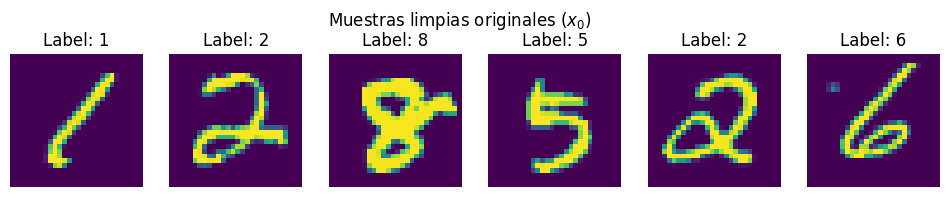

In [4]:
def min_max_to_01(img):
    """
    Escala un tensor arbitrario a [0, 1] usando su valor mínimo y máximo.

    Fórmula: (x - min) / (max - min)
    """
    img_min = img.min()
    img_max = img.max()

    if img_min == img_max:
        return torch.zeros_like(img)+0.5
    else:
        return (img - img_min) / (img_max - img_min)

# Transformación: a tensor y normalizar de [0, 1] a [-1, 1]
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))  # (x - 0.5) / 0.5 -> rango [-1, 1]
])

dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
dataloader = DataLoader(dataset, batch_size=16, shuffle=True)

# Extraemos un batch para inspeccionar las imágenes originales
images, labels = next(iter(dataloader))
print(f"Dimensiones del batch: {images.shape}")
print(f"Rango de valores: min={images.min().item():.2f}, max={images.max().item():.2f}")

NUM_FIGURES=6
# Visualizamos algunos dígitos limpios x_0
fig, axes = plt.subplots(1, NUM_FIGURES, figsize=(int(NUM_FIGURES*2), 2))
for idx in range(NUM_FIGURES):
    img = min_max_to_01(images[idx].squeeze())
    axes[idx].imshow(img, cmap=CMAP)
    axes[idx].set_title(f"Label: {labels[idx].item()}")
    axes[idx].axis("off")
plt.suptitle("Muestras limpias originales ($x_0$)", y=1.05)
plt.show()

# Forward Process

En la presente sección se describe el *forward process*, en el que se le inyecta ruido a la imagen.

Generamos ahora el el Schedule de ruido ($\beta_i, \alpha_i, \bar{\alpha}_i$)
- Se define una secuencia monótona creciente $\{\beta_i\}_{i=1}^L$ con $\beta_i \in \left]0, 1\right[$.
- Cada factor de retención del paso es $\alpha_i = \sqrt{1 - \beta_i^2}$.
- La acumulación de retención de señal desde el inicio hasta el paso $i$ es:
  $$\bar{\alpha}_i = \prod_{k=1}^i \alpha_k$$
- Con esto, la desviación estándar del ruido acumulado es $\sqrt{1 - \bar{\alpha}_i^2}$.

In [5]:
import torch

def get_noise_schedule(L=300, beta_0=0.0, beta_L=0.3):
    # Secuencia discreta de pasos i = 0, ..., L
    betas = torch.linspace(beta_0, beta_L, L + 1)

    # alpha_i = sqrt(1 - beta_i^2)
    alphas = torch.sqrt(1.0 - betas**2)

    # alpha_bar_i = prod_{k=0}^i alpha_k
    alphas_bar = torch.cumprod(alphas, dim=0)

    # Coeficiente de dispersión de ruido acumulado: sqrt(1 - alpha_bar_i^2)
    sqrt_one_minus_alphas_bar_sq = torch.sqrt(1.0 - alphas_bar**2)

    return L, beta_0, beta_L, betas, alphas, alphas_bar, sqrt_one_minus_alphas_bar_sq

L, beta_0, beta_L, betas, alphas, alphas_bar, sqrt_one_minus_alphas_bar_sq = get_noise_schedule(300, 0.0, 0.3)


print(f"Pasos totales configurados: {L}")
print(f"Paso 0:   alpha_bar = {alphas_bar[0]:.4f}, std_ruido = {sqrt_one_minus_alphas_bar_sq[0]:.4f}")
print(f"Paso {L}: alpha_bar = {alphas_bar[L]:.4f}, std_ruido = {sqrt_one_minus_alphas_bar_sq[L]:.4f}")

Pasos totales configurados: 300
Paso 0:   alpha_bar = 1.0000, std_ruido = 0.0000
Paso 300: alpha_bar = 0.0096, std_ruido = 1.0000


Graficamos cómo evolucionan los dos pesos a lo largo de los pasos $i \in [0, L]$:
- $\bar{\alpha}_i$: ponderación de la imagen original (debe decaer hacia 0).
- $\sqrt{1 - \bar{\alpha}_i^2}$: ponderación del ruido gaussiano (debe crecer hacia 1).

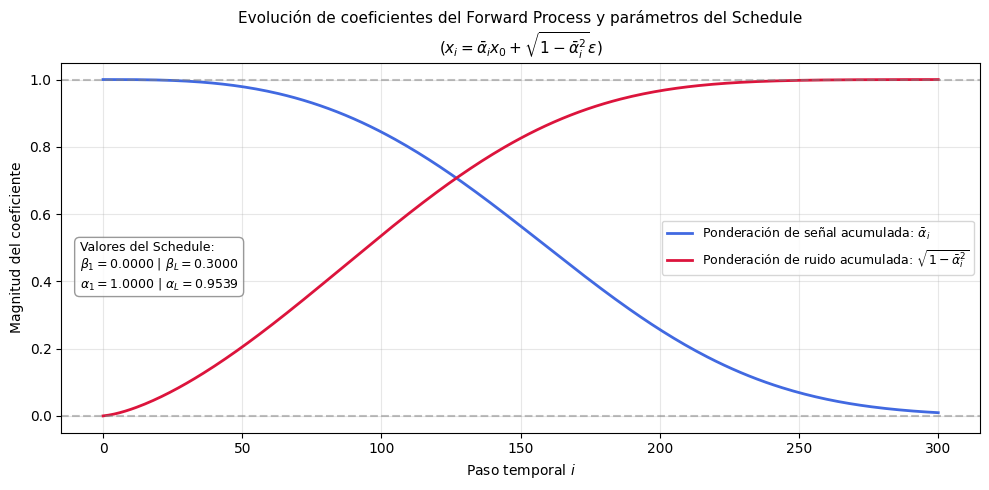

In [6]:
import matplotlib.pyplot as plt

# Extraer valores iniciales y finales del schedule
b_start = betas[0].item() if hasattr(betas[0], "item") else betas[0]
b_end = betas[-1].item() if hasattr(betas[-1], "item") else betas[-1]

steps = range(L + 1)

plt.figure(figsize=(10, 5))

# Curvas acumuladas (Forward Process hacia x_0)
plt.plot(
    steps, alphas_bar.numpy(),
    label=r"Ponderación de señal acumulada: $\bar{\alpha}_i$",
    color="royalblue", lw=2
)
plt.plot(
    steps, sqrt_one_minus_alphas_bar_sq.numpy(),
    label=r"Ponderación de ruido acumulada: $\sqrt{1 - \bar{\alpha}_i^2}$",
    color="crimson", lw=2
)

# Líneas de referencia
plt.axhline(0, color="gray", linestyle="--", alpha=0.5)
plt.axhline(1, color="gray", linestyle="--", alpha=0.5)

# Título y etiquetas
plt.title(
    r"Evolución de coeficientes del Forward Process y parámetros del Schedule"
    + f"\n" + r"($x_i = \bar{\alpha}_i x_0 + \sqrt{1-\bar{\alpha}_i^2}\epsilon$)",
    fontsize=11
)
plt.xlabel("Paso temporal $i$")
plt.ylabel("Magnitud del coeficiente")

# Caja informativa con los valores extremos
info_text = (
    f"Valores del Schedule:\n"
    f"$\\beta_1 = {b_start:.4f}$ | $\\beta_L = {b_end:.4f}$\n"
    f"$\\alpha_1 = {alphas[0].item():.4f}$ | $\\alpha_L = {alphas[-1].item():.4f}$"
)
plt.gca().text(
    0.02, 0.45, info_text, transform=plt.gca().transAxes,
    fontsize=9, verticalalignment="center",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="gray", alpha=0.8)
)

plt.legend(frameon=True, loc="center right", fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Gracias a la propiedad analítica de composición gaussiana, **no es necesario simular paso por paso**:
$$x_i = \bar{\alpha}_i x_0 + \sqrt{1 - \bar{\alpha}_i^2} \epsilon, \quad \text{donde } \epsilon \sim \mathcal{N}(0, \mathbf{I})$$
Con el scheduler fijado, tenemos efectivamente que $\{\bar{\alpha}_i\}\to 0$, luego la imagen converge a $\mathcal{N}(0, \mathbf{I})$.

Esta función permite obtener directamente el estado corrupto $x_i$ para cualquier paso $i$.

In [7]:
def q_sample(x_0, i, eps=None):
    """
    Corrompe una imagen limpia x_0 hasta el nivel i en un único paso cerrado.
    Retorna tanto la imagen ruidosa x_i como el ruido epsilon inyectado.
    """
    if eps is None:
        eps = torch.randn_like(x_0)

    # Extraemos coeficientes correspondientes a cada índice i del batch
    a_bar = alphas_bar[i].view(-1, 1, 1, 1)
    std = sqrt_one_minus_alphas_bar_sq[i].view(-1, 1, 1, 1)

    x_i = a_bar * x_0 + std * eps
    return x_i, eps

Comprobamos ahora visualmente una única imagen de MNIST y le aplicamos ruido a diferentes pasos temporales. Se observa cómo los trazos del dígito se van difuminando progresivamente hasta convertirse en ruido puramente aleatorio indistinguible de ruido blanco.

In [8]:
def run_forward_trajectory(x_0, L, q_sample_fn, fixed_noise=None, device="cuda"):
    if device is None:
        device = x_0.device
    else:
        x_0 = x_0.to(device)

    if fixed_noise is None:
        fixed_noise = torch.randn_like(x_0)
    else:
        fixed_noise = fixed_noise.to(device)

    trajectory = {}
    with torch.no_grad():
        for t in range(0, L + 1):
            # Aseguramos que el índice esté en el mismo dispositivo que x_0
            step_tensor = torch.tensor([t], device=x_0.device, dtype=torch.long)
            noisy_x, _ = q_sample_fn(x_0, step_tensor, eps=fixed_noise)
            trajectory[t] = noisy_x.detach()
    return trajectory

def plot_static_steps(trajectory, steps_to_show, alphas_bar, title="Evolución del Proceso"):
    """
    Grafica una fila de pasos estáticos a partir de una trayectoria precalculada.
    """
    fig, axes = plt.subplots(1, len(steps_to_show), figsize=(2.8 * len(steps_to_show), 3))
    if len(steps_to_show) == 1:
        axes = [axes]

    for idx, step in enumerate(steps_to_show):
        img = trajectory[step].squeeze().cpu()
        img_01 = min_max_to_01(img)

        axes[idx].imshow(img_01.numpy(), cmap=CMAP)
        axes[idx].set_title(f"Paso {step}\n$\\bar{{\\alpha}}$: {alphas_bar[step].item():.2f}")
        axes[idx].axis("off")

    plt.suptitle(title, y=1.05, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


def create_process_gif(
    trajectory,
    steps_sequence,
    alphas_bar,
    duration=60,
    pause_first_ms=1000,
    pause_last_ms=1000
):
    """
    Genera y muestra directamente un GIF a partir de una secuencia de pasos,
    permitiendo pausar más tiempo en el primer y último fotograma.
    """
    frames = []
    for step in steps_sequence:
        img = trajectory[step].squeeze().cpu()
        img_01 = min_max_to_01(img)

        fig, (ax_img, ax_text) = plt.subplots(1, 2, figsize=(5.5, 2.5), gridspec_kw={'width_ratios': [1, 1.2]})
        ax_img.imshow(img_01.numpy(), cmap=CMAP)
        ax_img.axis("off")
        ax_text.axis("off")

        info_text = (
            f"Paso actual: {step}\n\n"
            f"Señal ($\\bar{{\\alpha}}_i$):\n{alphas_bar[step].item():.4f}\n\n"
        )
        ax_text.text(0.1, 0.5, info_text, fontsize=12, va="center", family="sans-serif")
        plt.tight_layout()

        buf = io.BytesIO()
        plt.savefig(buf, format="png", dpi=100, bbox_inches="tight")
        plt.close(fig)
        buf.seek(0)
        frames.append(Image.open(buf).convert("RGB"))

    if not frames:
        return

    # Definimos la duración para cada fotograma individual
    durations = [duration] * len(frames)
    durations[0] = pause_first_ms      # Pausa en el fotograma inicial
    durations[-1] = pause_last_ms     # Pausa en el fotograma final

    # Compilar GIF en memoria pasando la lista de duraciones
    gif_buf = io.BytesIO()
    frames[0].save(
        gif_buf,
        format="GIF",
        save_all=True,
        append_images=frames[1:],
        duration=durations,
        loop=0
    )
    display(IPImage(data=gif_buf.getvalue()))

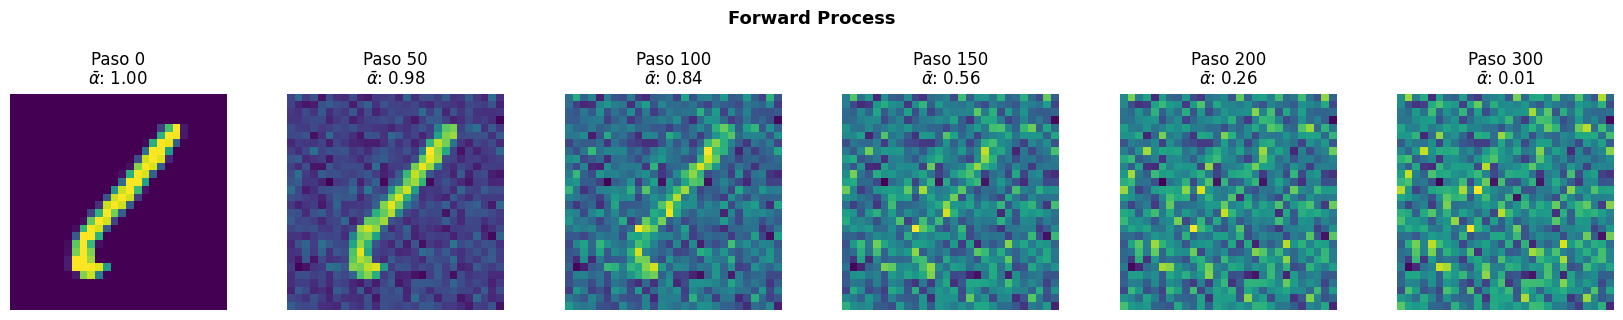

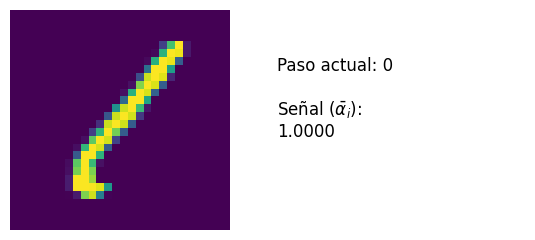

In [9]:
alphas_bar = alphas_bar.to(device)
sqrt_one_minus_alphas_bar_sq = sqrt_one_minus_alphas_bar_sq.to(device)

# 2. Ahora ejecuta el forward sin problemas
x_0_test = images[0:1].to(device)
traj_fwd = run_forward_trajectory(x_0_test, L=L, q_sample_fn=q_sample, device=device)

# 3. Estático Forward
plot_static_steps(traj_fwd, steps_to_show=[0, 50, 100, 150, 200, 300], alphas_bar=alphas_bar, title="Forward Process")

# 4. GIF Forward
pasos_gif_fwd = list(range(0, L+1, 5))
create_process_gif(traj_fwd, steps_sequence=pasos_gif_fwd, alphas_bar=alphas_bar)

# Reverse Process

Sabemos que la distribución reversa condicionada en el dato limpio $x_0$ es gaussiana y tiene forma cerrada:

$$p(x_{i-1} \mid x_i, x_0) = \mathcal{N}\left(x_{i-1};\, \mu(x_i, x_0, i),\, \sigma^2(i)\mathbf{I}\right)$$

donde sus parámetros exactos son:

$$\mu(x_i, x_0, i) := \frac{\bar{\alpha}_{i-1}\beta_i^2}{1 - \bar{\alpha}_i^2}x_0 + \frac{(1 - \bar{\alpha}_{i-1}^2)\alpha_i}{1 - \bar{\alpha}_i^2}x_i, \qquad \sigma^2(i) := \frac{1 - \bar{\alpha}_{i-1}^2}{1 - \bar{\alpha}_i^2}\beta_i^2$$

In [10]:
# 1. Aseguramos el cálculo de coeficientes para la media analítica mu(x_i, x_0, i)
# mu(x_i, x_0, i) = coef_x0 * x_0 + coef_xi * x_i
coef_x0 = torch.zeros(L + 1, device=device)
coef_xi = torch.zeros(L + 1, device=device)
sigma_sq = torch.zeros(L + 1, device=device)

alphas_bar = alphas_bar.to(device)
alphas = alphas.to(device)
betas = betas.to(device)

for i in range(1, L + 1):
    denom = 1.0 - alphas_bar[i]**2
    coef_x0[i] = (alphas_bar[i - 1] * (betas[i]**2)) / denom
    coef_xi[i] = ((1.0 - alphas_bar[i - 1]**2) * alphas[i]) / denom
    sigma_sq[i] = ((1.0 - alphas_bar[i - 1]**2) / denom) * (betas[i]**2)

# Evitar división por cero en i=1 para la pérdida ponderada
sigma_sq_safe = torch.clamp(sigma_sq, min=1e-8)


def get_true_reverse_mean(x_0, x_i, i_tensor):
    """Calcula mu(x_i, x_0, i) analíticamente para un batch"""
    c0 = coef_x0[i_tensor].view(-1, 1, 1, 1)
    ci = coef_xi[i_tensor].view(-1, 1, 1, 1)
    return c0 * x_0 + ci * x_i

El enfoque que se empleará es usar una red neuronal $\mu_\phi(x_i,i)$ que aproxime $\mu(x_i,i)$, pero antes de eso veamos cómo funciona la función `get_true_reverse_mean`.

En este experimento simulamos el proceso reverso ideal conociendo $x_0$, algo que normalmente no podremos hacer:
1. Partimos del estado de ruido máximo en el paso final $x_L \sim p_L(x_L \mid x_0)$ (prácticamente ruido puro).
2. Iteramos en cuenta regresiva desde $i = L$ hacia $i = 1$.
3. En cada paso calculamos la media analítica $\mu(x_i, x_0, i)$.

In [11]:
def run_backward_trajectory(x_0, L, q_sample_fn, get_mean_fn, sigmas, add_noise=True, device=None):
    if device is None:
        device = x_0.device
    else:
        x_0 = x_0.to(device)

    sigmas = sigmas.to(x_0.device)

    trajectory = {}
    with torch.no_grad():
        step_L_tensor = torch.tensor([L], device=x_0.device, dtype=torch.long)
        current_x, _ = q_sample_fn(x_0, step_L_tensor)
        trajectory[L] = current_x.detach()

        for i_val in range(L, 0, -1):
            mean = get_mean_fn(x_0, current_x, i_val)
            if add_noise and i_val > 1:
                noise = torch.randn_like(current_x)
                current_x = mean + sigmas[i_val] * noise
            else:
                current_x = mean

            trajectory[i_val - 1] = current_x.detach()
    return trajectory

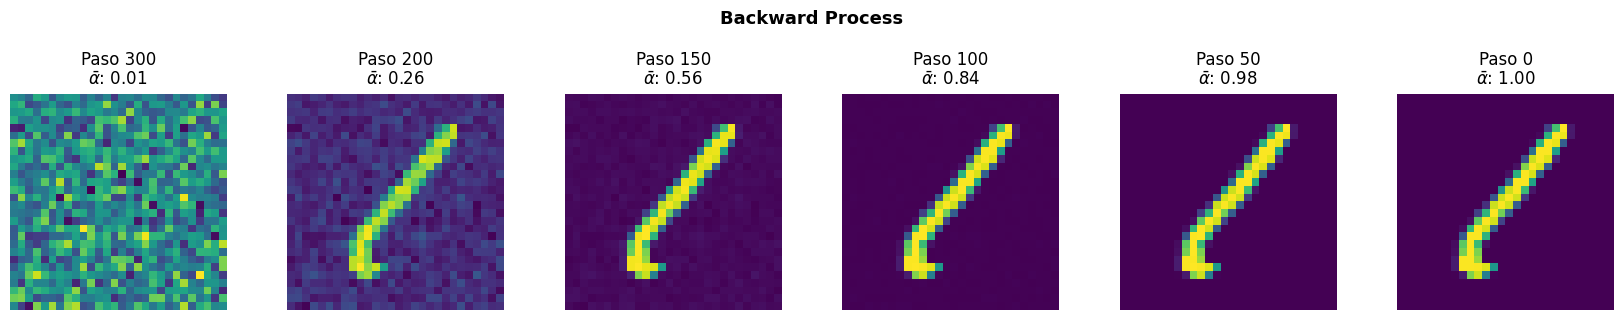

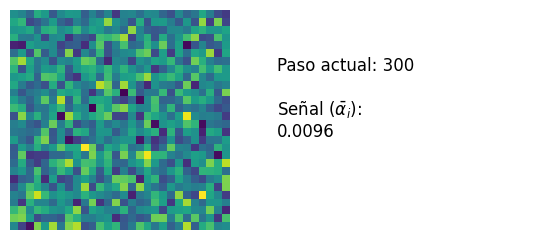

In [12]:
alphas_bar = alphas_bar.to(device)
sqrt_one_minus_alphas_bar_sq = sqrt_one_minus_alphas_bar_sq.to(device)
coef_x0 = coef_x0.to(device)
coef_xi = coef_xi.to(device)
sigmas = torch.sqrt(torch.clamp(sigma_sq, min=1e-20)).to(device)

traj_bwd = run_backward_trajectory(x_0_test, L=300, q_sample_fn=q_sample, get_mean_fn=get_true_reverse_mean, sigmas=sigmas, add_noise=False, device=device)

# 1. Estático Backward
plot_static_steps(traj_bwd, steps_to_show=[300, 200, 150, 100, 50, 0], alphas_bar=alphas_bar, title="Backward Process")

# 2. GIF Backward
pasos_gif_bwd = list(range(L, -1, -5))
create_process_gif(traj_bwd, steps_sequence=pasos_gif_bwd, alphas_bar=alphas_bar)

## 1. Mean Prediction

No obstante, durante la fase de generación (inferencia), **no tenemos acceso al dato limpio original $x_0$**; solo disponemos del estado ruidoso actual $x_i$.

Por lo tanto, la primera aproximación natural consiste en asumir que la distribución reversa no condicionada $p_\phi(x_{i-1} \mid x_i)$ mantiene la misma estructura gaussiana con la varianza analítica fija $\sigma^2(i)\mathbf{I}$, y entrenar una red neuronal para que aprenda a predecir directamente el vector de media:

$$p_\phi(x_{i-1} \mid x_i) := \mathcal{N}\left(x_{i-1};\, \mu_\phi(x_i, i),\, \sigma^2(i)\mathbf{I}\right)$$

#### ¿Qué representa la red $\mu_\phi(x_i, i)$?

* **Entrada**: Recibe el estado ruidoso actual $x_i$ y el índice temporal del paso $i$.
* **Salida**: Genera un vector con las mismas dimensiones que la imagen, $\mu_\phi(x_i, i)$, que representa el estado medio esperado en el paso anterior $i-1$.
* **Objetivo de aprendizaje**: Minimizar la divergencia KL entre la distribución condicional real y la aproximada equivale a un problema de regresión de mínimos cuadrados ponderado:

$$\mathcal{L}_{\text{DDPM}}(\phi) = \sum_{i=2}^L \frac{1}{2\sigma^2(i)} \mathbb{E}_{x_0, x_i \sim p_i(\cdot \mid x_0)} \left[ \|\mu_\phi(x_i, i) - \mu(x_i, x_0, i)\|_2^2 \right]$$

En resumen, bajo este esquema la red neuronal actúa directamente como un estimador de la media del siguiente paso menos ruidoso, intentando reproducir $\mu(x_i, x_0, i)$ sin conocer $x_0$.

#### Time Embedding


La red neuronal necesita saber en qué paso temporal $i$ está trabajando para estimar la cantidad adecuada de ruido o corrección (por ejemplo, saber si está en el paso $i = 5$ o en el $i = 300$).

Sin embargo, **no le pasamos el número entero $i$ directamente a la red**. En su lugar, transformamos ese valor en un **embedding**. Los motivos por los que no pasarle $i$ directamente son:

1. **Problemas de escala numérica:** Un valor como `300` es enorme para las activaciones y pesos de una red neuronal frente a valores iniciales como `1`. Puede provocar inestabilidades numéricas o saturar las capas.
2. **Pérdida de resolución al normalizar:** Si intentamos normalizar dividiendo por el total ($i / 300$), la diferencia entre dos pasos consecutivos (por ejemplo, el paso 5 y el 6) pasa a ser de apenas `0.0033`. En redes convolucionales profundas, diferencias escalares tan minúsculas tienden a diluirse y perderse por completo.
3. **Poca capacidad expresiva:** Un único valor escalar no tiene la riqueza matemática suficiente para interactuar con las decenas o cientos de canales de una capa convolucional.

Para resolver esto, le proporcionamos un **embedding**, que es simplemente una traducción: toma un concepto discreto (un número entero como el paso $i$) y lo convierte en un **vector continuo de muchas dimensiones** (por ejemplo, una lista de 64 números).

Cada paso temporal pasa a tener su propia "huella dactilar" o patrón vectorial único:
* Paso 1 $\rightarrow$ `[ 0.84, -0.54, 0.12, 0.99, ... 64 números ]`
* Paso 100 $\rightarrow$ `[-0.23,  0.91, -0.65, 0.03, ... 64 números ]`
* Paso 300 $\rightarrow$ `[ 0.15,  0.32,  0.88, -0.71, ... 64 números ]`


Para construir esos 64 números usamos ondas trigonométricas a distintas frecuencias, conocido como *Embedding Sinusoidal*:
* **Frecuencias altas (ondas rápidas):** Varían bruscamente entre pasos consecutivos, lo que permite a la red notar la diferencia sutil entre pasos vecinos ($i$ e $i - 1$).
* **Frecuencias bajas (ondas lentas):** Varían de forma suave a lo largo de todo el rango, lo que le permite a la red entender en qué etapa global del proceso se encuentra (principio, mitad o final).

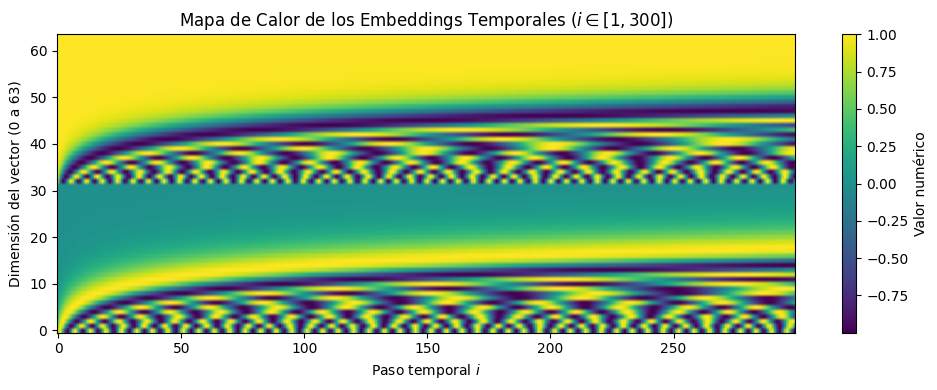

In [13]:
def get_sinusoidal_embedding(timesteps, dim):
    """
    Transforma un tensor 1D de pasos temporales [B]
    en una matriz de embeddings continuos [B, dim].
    """
    half_dim = dim // 2
    emb_scale = math.log(10000) / (half_dim - 1)
    # Frecuencias decrecientes
    freqs = torch.exp(torch.arange(half_dim, device=timesteps.device) * -emb_scale)
    # Argumento angular: timesteps x frecuencias
    args = timesteps.float()[:, None] * freqs[None, :]
    # Combinamos senos y cosenos
    return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)

# Calculamos los embeddings de todos los pasos disponibles
todos_los_pasos = torch.arange(1, L + 1, device=device)
dim_emb = 64
matriz_embeddings = get_sinusoidal_embedding(todos_los_pasos, dim=dim_emb).cpu()

# Visualizamos la matriz de embeddings completa como un mapa de calor
plt.figure(figsize=(10, 4))
plt.imshow(matriz_embeddings.t().numpy(), aspect="auto", cmap="viridis", origin="lower")
plt.title(f"Mapa de Calor de los Embeddings Temporales ($i \\in [1, {L}]$)")
plt.xlabel("Paso temporal $i$")
plt.ylabel("Dimensión del vector (0 a 63)")
plt.colorbar(label="Valor numérico")
plt.tight_layout()
plt.show()

Veamos cómo interpretar este mapa de color.

* **Eje horizontal ($x$):** Representa el paso temporal $i$ avanzando desde $1$ hasta $L$.
* **Eje vertical ($y$):** Representa las 64 componentes del vector que describe a ese paso.
* **Zona inferior (índices bajos):** Ondas de alta frecuencia que alternan con rapidez entre positivo (amarillo) y negativo (azul/morado).
* **Zona superior (índices altos):** Ondas lentas que evolucionan de forma continua y suave.

Cada columna vertical de esta imagen es un vector único que se proyecta y se suma a las características de la imagen dentro de la red, permitiéndole modular su comportamiento según la fase de ruido en la que se encuentre.

#### Función de Pérdida $\mathcal{L}_{\text{DDPM}}$ mediante Muestreo Monte Carlo

La pérdida se define como una suma sobre todos los pasos temporales:
$$\mathcal{L}_{\text{DDPM}}(\phi) = \sum_{i=2}^L \frac{1}{2\sigma^2(i)} \mathbb{E}_{x_0, x_i} \left[ \|\mu_\phi(x_i, i) - \mu(x_i, x_0, i)\|_2^2 \right]$$

Si calculáramos la suma exacta en cada iteración, tendríamos que pasar cada imagen del lote $L - 1$ veces por la red neuronal, lo cual multiplicaría el tiempo de cómputo por cientos.

Para evitar esto, aplicamos la técnica estándar de **aproximación por Monte Carlo**:
1. Para cada imagen del lote, seleccionamos un paso temporal $i \in \{2, \dots, L\}$ de forma aleatoria y uniforme.
2. Evaluamos la discrepancia cuadrática ponderada por la varianza $\frac{1}{2\sigma^2(i)}$ en ese paso concreto.
3. El promedio de estas pérdidas a lo largo de las iteraciones es un **estimador insesgado** de la suma global, reduciendo drásticamente el coste computacional.

In [14]:
def compute_ddpm_mean_loss_sampled(model, x_0):
    """
    Calcula la perdida L_DDPM mediante estimacion Monte Carlo:
    se muestrea un i aleatorio uniforme en [2, L] para cada muestra del batch.
    """
    batch_size = x_0.shape[0]

    # 1. Muestreamos pasos aleatorios uniformes en {0, ..., L}
    i_samples = torch.randint(0, L + 1, (batch_size,), device=device).long()

    # 2. Corrompemos el batch a x_i
    x_i, _ = q_sample(x_0, i_samples)

    target_mu = get_true_reverse_mean(x_0, x_i, i_samples)

    # 4. Prediccion de la red densa
    pred_mu = model(x_i, i_samples)

    # 5. Termino ponderado por la varianza sigma^2(i) (Ecuacion 2.2.8)
    variances = sigma_sq[i_samples].view(-1, 1, 1, 1)
    loss_per_pixel = (pred_mu - target_mu) ** 2
    weighted_loss = loss_per_pixel / (2.0 * variances)

    return weighted_loss.mean()

#### Arquitectura Inicial: Red Neuronal Estándar

Inicialmente, emplearemos una **red neuronal estándar completamente conectada (MLP)**, una red densa estándar.


1. **Aplanar la imagen (*Flatten*):**
   La imagen ruidosa $x_i$ tiene unas dimensiones de $1 \times 28 \times 28$ píxeles. La desplegamos como un vector unidimensional de $784$ números continuos ($28 \times 28 = 784$).

2. **Unir imagen y tiempo (*Concatenación*):**
   El paso temporal $i$ se transforma primero en un vector continuo de $64$ números usando el *embedding* sinusoidal visto anteriormente.
   Luego, simplemente pegamos ambos vectores:
   $$\text{Vector de entrada} = [\,\text{784 píxeles de la imagen},\; \text{64 valores del embedding del tiempo}\,] \longrightarrow \text{Longitud total: } 848$$

3. **Capas ocultas estándar (`nn.Linear`):**
   Ese vector de $848$ valores entra por capas densas convencionales:
   * **Capa 1:** Pasa de $848$ entradas a $256$ neuronas intermedias, seguida de una activación no lineal (`SiLU`).
   * **Capa 2:** Mantiene las $256$ neuronas para procesar las relaciones entre el nivel de ruido y la posición de los trazos.

4. **Capa de salida y reconstrucción (*Reshape*):**
   La última capa lineal proyecta las $256$ neuronas de vuelta a $784$ valores de salida. Finalmente, reordenamos ese vector a su forma original de imagen de $1 \times 28 \times 28$.
   
El resultado es directamente el tensor $\mu_\phi(x_i, i)$ predicho.

In [15]:
class MLPMeanDiffusionModel(nn.Module):
    def __init__(self, img_dim=784, time_dim=64, hidden_dim=256):
        super().__init__()
        self.img_dim = img_dim
        self.time_dim = time_dim

        # Entrada total: 784 (píxeles) + 64 (embedding de tiempo) = 848
        in_features = img_dim + time_dim

        self.net = nn.Sequential(
            # Capa 1: 848 -> 256
            nn.Linear(in_features, hidden_dim),
            nn.SiLU(),
            # Capa 2: 256 -> 256
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            # Capa de salida: 256 -> 784
            nn.Linear(hidden_dim, img_dim)
        )

    def forward(self, x_i, i):
        # 1. Aplanar la imagen (Flatten): [B, 1, 28, 28] -> [B, 784]
        b = x_i.shape[0]
        x_flat = x_i.view(b, -1)

        # 2. Obtener el embedding sinusoidal del paso temporal i [B, 64]
        t_emb = get_sinusoidal_embedding(i, self.time_dim)

        # Concatenar imagen (784) y tiempo (64) -> [B, 848]
        inp = torch.cat([x_flat, t_emb], dim=-1)

        # 3. Capas densas intermedias
        out = self.net(inp)

        # 4. Reconstrucción (Reshape): [B, 784] -> [B, 1, 28, 28]
        return out.view_as(x_i)

Aunque el lector podrá pensar que este modelo funciona, si analizamos nuestro *noise schedule*, observamos un problema crítico de estabilidad numérica en los primeros pasos temporales ($i \approx 0$):

1. **Paso inicial ($i = 0$):** Al inicio del proceso no hay ruido inyectado ($\beta_0 = 0$), lo que implica que la retención de señal es total ($\bar{\alpha}_0 = 1.0$).
2. **Dispersión nula:** En consecuencia, la desviación estándar acumulada es exactamente cero:
   $$\sigma_0 = \sqrt{1 - 1.0^2} = 0$$
3. **División por cero y explosión de gradientes:** Al intentar evaluar el factor de escala $\frac{1}{\sigma_i^2}$, para $i = 0$ se produce una **división por cero**, y para valores pequeños de $i$ el factor crece exponencialmente hacia el infinito ($\infty$).

Esto provoca que la función de pérdida se desborde de forma inmediata a valores `Inf` o `NaN`, imposibilitando el entrenamiento del optimizador. Podemos evitar justo el caso $i=0$, pero para valores pequeños de $i$, esa división producirá desbordamientos.

A continuación, visualizamos la evolución de $\sigma_i$ y su factor de ponderación inversa $\frac{1}{\sigma_i^2}$ para evidenciar en qué pasos se produce esta asíntota numérica.

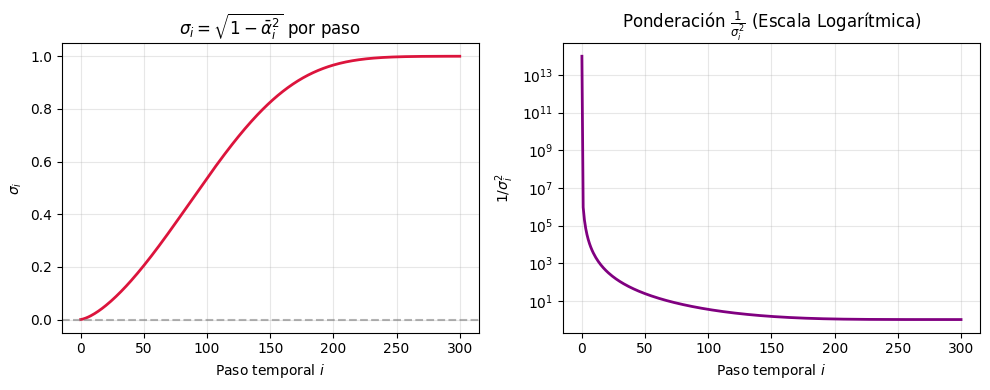

In [16]:
sigmas = sqrt_one_minus_alphas_bar_sq.cpu()
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(range(L + 1), sigmas.numpy(), color="crimson", lw=2)
plt.axhline(0, color="gray", linestyle="--", alpha=0.6)
plt.title(r"$\sigma_i = \sqrt{1 - \bar{\alpha}_i^2}$ por paso")
plt.xlabel("Paso temporal $i$")
plt.ylabel(r"$\sigma_i$")
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
# Reemplazamos 0 por un umbral para poder visualizar en escala logarítmica
inv_sigmas_sq = 1.0 / (torch.clamp(sigmas, min=1e-7) ** 2)
plt.plot(range(L + 1), inv_sigmas_sq.numpy(), color="purple", lw=2)
plt.yscale("log")
plt.title(r"Ponderación $\frac{1}{\sigma_i^2}$ (Escala Logarítmica)")
plt.xlabel("Paso temporal $i$")
plt.ylabel(r"$1 / \sigma_i^2$")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Configuramos el entrenamiento de un modelo mediante esta función genérica, que además nos permite cargar la información del modelo entrenado.

In [17]:
import os
import copy
import torch
from tqdm.auto import tqdm

def train_or_load_model(
    model,
    dataloader,
    optimizer,
    loss_fn,
    file_name,
    epochs=10,
    train=False,
    device=None,
    scheduler=None,      # OneCycleLR o similar (se llama una vez por batch)
    grad_clip=None,      # p.ej. 1.0
    ema_decay=None,      # p.ej. 0.999; None = sin EMA
):
    device = device or globals().get("device", "cpu")
    model = model.to(device)
    weights_path = os.path.join(DRIVE_DIR, file_name)
    history_path = os.path.join(DRIVE_DIR, file_name.replace(".pth", "_loss.pt"))
    loss_history = []

    if train:
        print(f"-> Entrenando {model.__class__.__name__} ({epochs} épocas)...")

        ema_model = None
        if ema_decay is not None:
            ema_model = copy.deepcopy(model).eval()
            for p in ema_model.parameters():
                p.requires_grad_(False)

        global_step = 0
        desbordado = False
        pbar_epochs = tqdm(range(epochs), desc="Progreso Global (Épocas)", leave=True)

        for epoch in pbar_epochs:
            if desbordado:
                break

            model.train()
            running_loss = 0.0
            pbar_batches = tqdm(dataloader, desc=f"Época {epoch + 1}/{epochs}", leave=False)

            for batch_idx, (x_0, _) in enumerate(pbar_batches):
                x_0 = x_0.to(device)
                loss = loss_fn(model, x_0)

                if torch.isnan(loss) or torch.isinf(loss):
                    tqdm.write(f"\n[ERROR] Inestabilidad en Época {epoch + 1}, Batch {batch_idx}.")
                    desbordado = True
                    pbar_batches.close()
                    break

                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                if grad_clip is not None:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
                optimizer.step()
                if scheduler is not None:
                    scheduler.step()

                if ema_model is not None:
                    global_step += 1
                    d = min(ema_decay, (1 + global_step) / (10 + global_step))
                    with torch.no_grad():
                        for p_e, p in zip(ema_model.parameters(), model.parameters()):
                            p_e.mul_(d).add_(p.detach(), alpha=1 - d)
                        # Buffers (running_mean/var de BatchNorm): copiar tal cual
                        for b_e, b in zip(ema_model.buffers(), model.buffers()):
                            b_e.copy_(b)

                running_loss += loss.item()
                pbar_batches.set_postfix({"Loss": f"{loss.item():.4e}"})

            if not desbordado:
                avg_loss = running_loss / len(dataloader)
                loss_history.append(avg_loss)
                pbar_epochs.set_postfix({"Avg Loss": f"{avg_loss:.4e}"})

        if not desbordado:
            # Si hay EMA, el modelo final es el EMA
            final_model = ema_model if ema_model is not None else model
            torch.save(final_model.state_dict(), weights_path)
            torch.save(loss_history, history_path)
            print(f"-> Pesos{' EMA' if ema_model is not None else ''} e historial guardados en: '{weights_path}'.")
            model = final_model
        else:
            print("-> Entrenamiento interrumpido por inestabilidad. No se guardó nada.")

        model.eval()

    else:
        if not os.path.exists(weights_path):
            raise FileNotFoundError(
                f"No se encontró el archivo de pesos: '{weights_path}'. "
                "Debes ejecutar con `train=True` para entrenar y guardarlo."
            )
        if not os.path.exists(history_path):
            raise FileNotFoundError(
                f"No se encontró el archivo de historial de pérdidas: '{history_path}'. "
                "Debes ejecutar con `train=True` para entrenar y generarlo."
            )
        model.load_state_dict(torch.load(weights_path, map_location=device))
        model.eval()
        loss_history = torch.load(history_path, map_location="cpu")
        print(f"-> Pesos e historial cargados correctamente desde: '{weights_path}'.")

    return model, loss_history

In [18]:
EPOCHS = 25
MAX_LR = 1e-3

model_MLP = MLPMeanDiffusionModel()
opt_MLP = optim.AdamW(model_MLP.parameters(), lr=MAX_LR, weight_decay=0.0)
sched_MLP = optim.lr_scheduler.OneCycleLR(
    opt_MLP, max_lr=MAX_LR,
    total_steps=EPOCHS * len(dataloader),
    pct_start=0.05, anneal_strategy="cos",
)

model_MLP, history_MLP = train_or_load_model(
    model=model_MLP,
    dataloader=dataloader,
    optimizer=opt_MLP,
    loss_fn=compute_ddpm_mean_loss_sampled,
    file_name="model_eps_MLP.pth",
    epochs=EPOCHS,
    train=True,
    scheduler=sched_MLP,
    grad_clip=1.0,
    ema_decay=0.999,
)

-> Entrenando MLPMeanDiffusionModel (25 épocas)...


Progreso Global (Épocas):   0%|          | 0/25 [00:00<?, ?it/s]

Época 1/25:   0%|          | 0/3750 [00:00<?, ?it/s]


[ERROR] Inestabilidad en Época 1, Batch 67.
-> Entrenamiento interrumpido por inestabilidad. No se guardó nada.


Una alternativa intuitiva para evitar la inestabilidad numérica provocada por el factor $\frac{1}{\sigma_i^2}$ en la formulación original consistiría en **descartar directamente este término de ponderación** y entrenar la red minimizando un error cuadrático medio (MSE) no ponderado entre las medias:

$$\mathcal{L}_{\text{DDPM-Simple}}(\phi) = \mathbb{E}_{i,x_0, x_i} \left[ \|\mu_\phi(x_i, i) - \mu(x_i, x_0, i)\|_2^2 \right]$$

Desde un punto de vista puramente computacional, esto resolvería la división por cero y evitaría los valores `Inf` o `NaN`. Sin embargo, esta solución no es viable en la práctica porque el factor de ponderación es estrictamente necesario para balancear el aprendizaje a lo largo de los distintos pasos temporales.


* **Pasos pequeños ($i \approx 0$):** El nivel de ruido acumulado es mínimo ($\bar{\alpha}_i \approx 1$). En esta etapa, la media contiene casi la totalidad de la imagen limpia original ($\mu \approx x_0$), por lo que el vector objetivo presenta normas y varianzas grandes con todos los detalles nítidos de los dígitos.
* **Pasos grandes ($i \approx L$):** La retención de señal original se aproxima a cero ($\bar{\alpha}_L \approx 0$). Por tanto, la media colapsa analíticamente hacia el vector nulo ($\mu \approx \mathbf{0}$).

Si se elimina el factor de ponderación:

* El error cuadrático medio en los pasos avanzados ($i \approx L$) se vuelve intrínsecamente diminuto debido a que el objetivo a predecir ya es numéricamente muy cercano a cero.
* Los pasos iniciales de refinamiento ($i \approx 0$) dominan casi en su totalidad los gradientes del optimizador.
* Como consecuencia, la red neuronal descuida el aprendizaje en los niveles altos de ruido ($i \approx L$), que son precisamente los pasos cruciales en el proceso generativo inverso donde el modelo debe aprender a estructurar la forma global de la imagen a partir de ruido puro.

El factor original $\frac{1}{\sigma_i^2}$ actúa precisamente como un **mecanismo de compensación y balanceo**. Al quitarlo, se rompe este equilibrio; y al mantenerlo, la cercanía a $\sigma_i \to 0$ provoca el desbordamiento numérico.

Como conclusión, se deduce que debemos cambiar de estrategia.

## 2. Noise Prediction

Al reparametrizar la media estimada $\mu_\phi(x_i, i)$ en función del ruido inyectado:
$$\mu_\phi(x_i, i) = \frac{1}{\alpha_i} \left( x_i - \frac{1 - \alpha_i^2}{\sqrt{1 - \bar{\alpha}_i^2}} \epsilon_\phi(x_i, i) \right)$$

La discrepancia con la media real ${\mu}(x_i, x_0, i)$ se transforma directamente en un error sobre el ruido:
$$\|\mu_\phi(x_i, i) - {\mu}(x_i, x_0, i)\|_2^2 = \frac{(1 - \alpha_i^2)^2}{\alpha_i^2 (1 - \bar{\alpha}_i^2)} \|\epsilon_\phi(x_i, i) - \epsilon\|_2^2$$

Al sustituirlo en la pérdida original $\mathcal{L}_{\text{DDPM}}$, se llega a la función de pérdida:
$$\mathcal{L}_{\text{DDPM}}(\phi) = \sum_{i=2}^L w(i)\  \mathbb{E}_{x_0, x_i} \left[ \|\epsilon_\phi(x_i, i) - \epsilon\|_2^2 \right]$$

Notemos no obstante que dicho factor de ponderación podría seguir causando problemas, pero en este caso se puede eliminar puesto que los valores del ruido no dependen del valor de $i$ (siempre se muestrean de $\mathcal{N}(0,\mathbf{I})$. Por tanto, tenemos que:
$$\mathcal{L}_{\text{DDPM-SIMPLE}}(\phi) = \sum_{i=2}^L \mathbb{E}_{x_0, x_i} \left[ \|\epsilon_\phi(x_i, i) - \epsilon\|_2^2 \right]$$

Cabe destacar que minimizando ambas funciones de pérdida llegamos al mismo valor de los parámetros.

Al tratarse la estimación de Monte Carlo de un estimador insesgado, tenemos que:
$$\mathcal{L}_{\text{DDPM-SIMPLE}}(\phi) = \mathbb{E}_{i, x_0, \epsilon} \left[ \Vert{}\epsilon_\phi(x_i, i) - \epsilon\Vert{}_2^2 \right]$$

El procedimiento por pasos mediante aproximación de Monte Carlo es:
1. Muestrear un paso temporal $i \in \{1, \dots, L\}$ uniforme para cada imagen del batch.
2. Generar ruido gaussiano $\epsilon \sim \mathcal{N}(0, \mathbf{I})$ y corromper la imagen original para obtener $x_i$ usando `q_sample(x_0, i, eps=noise)`.
3. Predecir el ruido residual mediante la red: $\epsilon_{\text{pred}} = \text{model}(x_i, i)$.
4. Calcular el error cuadrático medio frente al ruido real inyectado.

#### Arquitectura: Red Neuronal Estándar para Predicción de Ruido

Al igual que en la aproximación anterior, inicialmente utilizaremos una **red neuronal estándar completamente conectada (MLP)**.

La estructura interna es idéntica a la empleada en la predicción de la media, con la única diferencia conceptual de que ahora la salida de la red no representa la imagen limpia promedio, sino **el ruido gaussiano $\epsilon_\phi(x_i, i)$** inyectado en el paso $i$:

1. **Aplanar la imagen ruidosa (*Flatten*):**
   La imagen ruidosa $x_i$ ($1 \times 28 \times 28$) se despliega como un vector unidimensional de $784$ elementos continuos ($28 \times 28 = 784$).

2. **Unir imagen ruidosa y tiempo (*Concatenación*):**
   El paso temporal $i$ se transforma en un vector continuo de $64$ valores usando el *embedding* sinusoidal visto anteriormente.
   Luego, concatenamos ambos vectores:
   $$\text{Vector de entrada} = [\,\text{784 píxeles de la imagen ruidosa},\; \text{64 valores del embedding del tiempo}\,] \longrightarrow \text{Longitud total: } 848$$

3. **Capas ocultas estándar (`nn.Linear`):**
   Ese vector de $848$ valores pasa por capas densas convencionales:
   - **Capa 1:** Pasa de $848$ entradas a $256$ neuronas intermedias, seguida de una activación no lineal (`SiLU`).
   - **Capa 2:** Mantiene las $256$ neuronas para aprender a identificar qué patrones corresponden al ruido artificial en función del instante $i$.

4. **Capa de salida y reconstrucción (*Reshape*):**
   La última capa lineal proyecta las $256$ neuronas de vuelta a $784$ valores de salida. Finalmente, reordenamos ese vector a su forma original de $1 \times 28 \times 28$.
   
El resultado es directamente el tensor de ruido $\epsilon_\phi(x_i, i)$ predicho (con la misma forma y escala que el ruido original $\epsilon$).

In [19]:
def compute_ddpm_noise_loss_sampled(model, x_0):
    """
    Calcula la perdida simplificada L_DDPM-SIMPLE mediante estimacion Monte Carlo:
    se muestrea un i aleatorio uniforme en [1, L] y se calcula el error cuadratico
    medio entre el ruido inyectado epsilon y la prediccion epsilon_phi(x_i, i).
    """
    batch_size = x_0.shape[0]

    # 1. Muestreamos pasos aleatorios uniformes en {1, ..., L}
    i_samples = torch.randint(1, L + 1, (batch_size,), device=device).long()

    # 2. Generamos el ruido real inyectado epsilon ~ N(0, I)
    noise = torch.randn_like(x_0)

    # 3. Corrompemos el batch a x_i conservando el ruido utilizado
    x_i, target_noise = q_sample(x_0, i_samples, eps=noise)

    # 4. Prediccion del ruido por parte de la red neuronal
    pred_noise = model(x_i, i_samples)

    # 5. Error cuadratico medio directo (L_simple) sin ponderacion por sigma^2(i)
    loss = F.mse_loss(pred_noise, target_noise)

    return loss

In [20]:
class MLPNoiseDiffusionModel(nn.Module):
    def __init__(self, img_dim=784, time_dim=64, hidden_dim=256):
        super().__init__()
        self.img_dim = img_dim
        self.time_dim = time_dim

        # Entrada total: 784 (píxeles de x_i) + 64 (embedding de tiempo) = 848
        in_features = img_dim + time_dim

        self.net = nn.Sequential(
            # Capa 1: 848 -> 256
            nn.Linear(in_features, hidden_dim),
            nn.SiLU(),
            # Capa 2: 256 -> 256
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            # Capa de salida: 256 -> 784 (ruido predicho)
            nn.Linear(hidden_dim, img_dim)
        )

    def forward(self, x_i, i):
        # 1. Aplanar la imagen ruidosa (Flatten): [B, 1, 28, 28] -> [B, 784]
        b = x_i.shape[0]
        x_flat = x_i.view(b, -1)

        # 2. Obtener el embedding sinusoidal del paso temporal i [B, 64]
        t_emb = get_sinusoidal_embedding(i, self.time_dim)

        # Concatenar imagen ruidosa (784) y tiempo (64) -> [B, 848]
        inp = torch.cat([x_flat, t_emb], dim=-1)

        # 3. Capas densas intermedias
        out = self.net(inp)

        # 4. Reconstrucción (Reshape): [B, 784] -> [B, 1, 28, 28]
        # El resultado devuelto es epsilon_phi(x_i, i)
        return out.view_as(x_i)

In [21]:
EPOCHS = 25
MAX_LR = 1e-3

model_MLP = MLPNoiseDiffusionModel()
opt_MLP = optim.AdamW(model_MLP.parameters(), lr=MAX_LR, weight_decay=0.0)
sched_MLP = optim.lr_scheduler.OneCycleLR(
    opt_MLP, max_lr=MAX_LR,
    total_steps=EPOCHS * len(dataloader),
    pct_start=0.05, anneal_strategy="cos",
)

model_MLP, history_MLP = train_or_load_model(
    model=model_MLP,
    dataloader=dataloader,
    optimizer=opt_MLP,
    loss_fn=compute_ddpm_noise_loss_sampled,
    file_name="model_eps_MLP.pth",
    epochs=EPOCHS,
    train=False,
    device=device,
    scheduler=sched_MLP,
    grad_clip=1.0,
    ema_decay=0.999,
)

-> Pesos e historial cargados correctamente desde: '/content/drive/MyDrive/modelos_difusion/model_eps_MLP.pth'.


Veamos si, efectivamente, la red neuronal ha aprendido lo buscado o no. Hay una gráfica interesante:
- Las épocas frente a la pérdida media en cada época: Esta debería tender a $0$ (puesto que necesitamos que se aprenda bien cómo se ha inyectado el ruido). Una curva descendente y continuada nos confirmará que el proceso de optimización funciona y que el modelo va asimilando progresivamente el mapeo de desruido tras cada iteración sobre el conjunto de datos.

En el caso de que la primera gráfica informe que se aprenden los datos, la siguiente gráfica puede ser de ayuda:
- El tiempo $i$ frente a la pérdida media en cada paso. Nos permite desglosar la capacidad de predicción del modelo según el nivel de ruido presente en la imagen. En condiciones ideales, el error debe mantenerse reducido a lo largo de todo el proceso de difusión; sin embargo, en pasos intermedios (donde la señal y el ruido se mezclan con mayor complejidad) es habitual observar cómo la arquitectura es puesta a prueba frente a la reconstrucción de bordes y coherencia global.

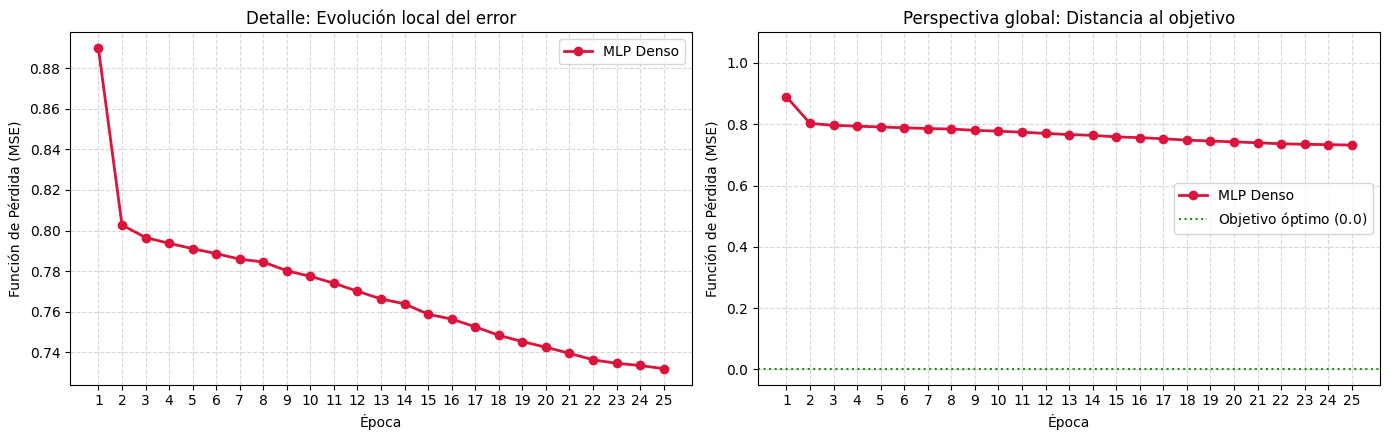

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
epochs_mlp = range(1, len(history_MLP) + 1)

# ---------------------------------------------
# Gráfica 1: Zoom en la evolución del MLP
# ---------------------------------------------
ax1.plot(epochs_mlp, history_MLP, marker="o", color="crimson", linewidth=2, label="MLP Denso")
ax1.set_title("Detalle: Evolución local del error")
ax1.set_xlabel("Época")
ax1.set_ylabel("Función de Pérdida (MSE)")
ax1.set_xticks(list(epochs_mlp))
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# ---------------------------------------------
# Gráfica 2: Perspectiva global (Escala completa 0 a 1)
# ---------------------------------------------
ax2.plot(epochs_mlp, history_MLP, marker="o", color="crimson", linewidth=2, label="MLP Denso")
ax2.axhline(0.0, color="forestgreen", linestyle=":", linewidth=1.5, label="Objetivo óptimo ($0.0$)")

ax2.set_ylim(-0.05, 1.1)
ax2.set_title("Perspectiva global: Distancia al objetivo")
ax2.set_xlabel("Época")
ax2.set_ylabel("Función de Pérdida (MSE)")
ax2.set_xticks(list(epochs_mlp))
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="center right")

plt.tight_layout()
plt.show()

Como podemos ver, aunque en la gráfica de la izquierda parezca que aprende, en realidad se queda bastante lejos del valor óptimo que debería aprender. Este concepto se conoce como el **Colapso del MLP**.

A partir de la ecuación del proceso forward:
$$x_i = \bar{\alpha}_i x_0 + \sqrt{1 - \bar{\alpha}_i^2} \, \epsilon$$

Si el modelo predice una estimación del ruido ${\epsilon}_\phi(x_i, i)$, podemos despejar analíticamente una aproximación directa de la imagen original en un único paso sin necesidad de realizar todo el muestreo inverso paso a paso:
$$\hat{x}_0 = \frac{x_i - \sqrt{1 - \bar{\alpha}_i^2} \, {\epsilon}_\phi(x_i, i)}{\bar{\alpha}_i}$$

Esta función permite inspeccionar visualmente la calidad de esa reconstrucción a mitad del proceso de difusión ($i = L/2$):

* **Original ($x_0$):** Imagen limpia de referencia tomada del conjunto de datos.
* **Ruidosa ($x_i$):** Imagen tras haberle añadido ruido gaussiano en el paso temporal seleccionado. Notemos que no se ha llegado a convertir en ruido puro, luego en teoría debería ser más sencillo de recuperar.
* **Predicción ($\hat{x}_0$):** Resultado de eliminar el ruido predicho por la red en una sola operación.

El **Colapso del MLP a la media** se evidencia aquí: en lugar de recuperar trazos nítidos y coherentes, la red tiende a devolver un promedio borroso o manchas amorfas de baja frecuencia.

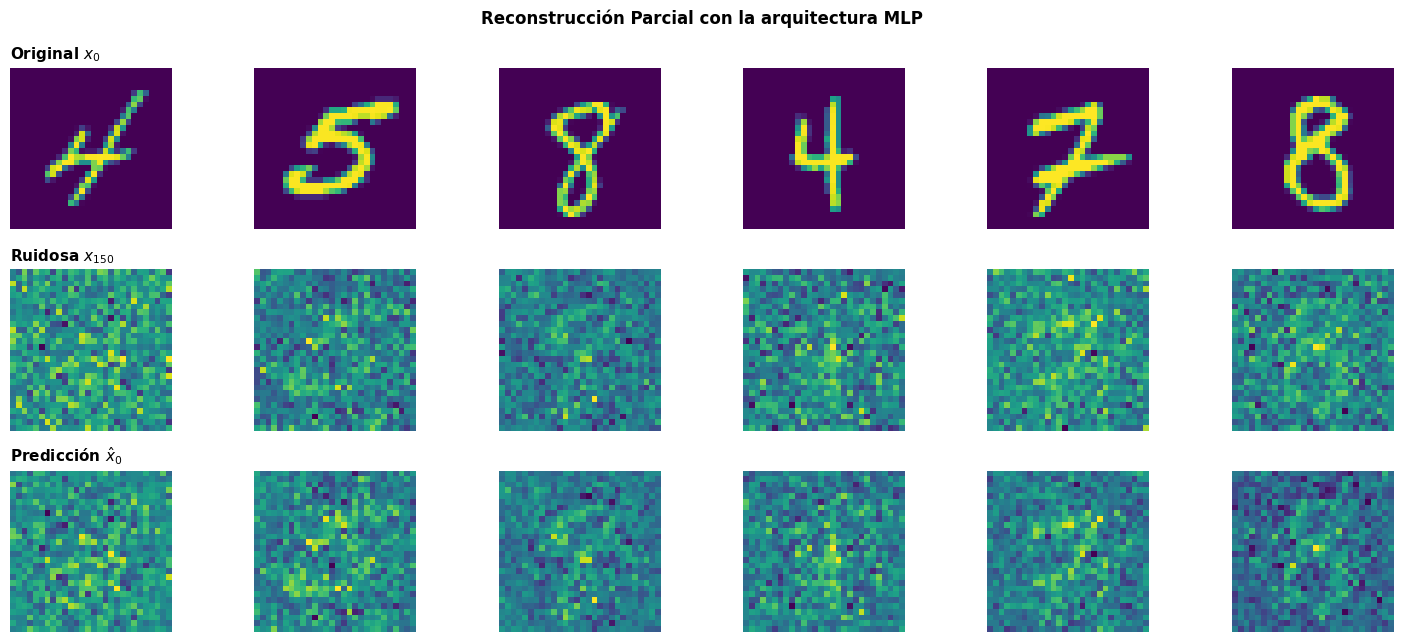

In [23]:
import torch
import matplotlib.pyplot as plt

@torch.no_grad()
def plot_one_step_reconstruction(
    model,
    dataloader,
    step=150,
    n=6,
    prediction_type="noise",  # "noise" o "x_0"
    title="Proceso de Reconstrucción",
    device=device,
):
    """
    Visualiza la reconstrucción en un solo paso comparando:
    Fila 1: Imagen original x_0
    Fila 2: Imagen ruidosa x_t
    Fila 3: Predicción o despeje de hat{x}_0
    """
    model.eval()
    x_0, _ = next(iter(dataloader))
    x_0 = x_0[:n].to(device)

    # 1. Corrupción usando el paso temporal definido
    i = torch.full((n,), step, device=device, dtype=torch.long)
    noise = torch.randn_like(x_0)
    x_i, _ = q_sample(x_0, i, eps=noise)

    # 2. Inferencia y obtención de x_0_pred
    out = model(x_i, i)
    if prediction_type == "noise":
        a_bar = alphas_bar[i].view(-1, 1, 1, 1).to(device)
        std_noise = sqrt_one_minus_alphas_bar_sq[i].view(-1, 1, 1, 1).to(device)
        x_0_pred = (x_i - std_noise * out) / a_bar.clamp(min=1e-12)
    elif prediction_type == "x_0":
        x_0_pred = out
    else:
        raise ValueError(f"prediction_type desconocido: {prediction_type}. Usa 'noise' o 'x_0'.")

    # 3. Gráfico comparativo (corregido figsize=(2.5 * n, 6.5))
    fig, axes = plt.subplots(3, n, figsize=(2.5 * n, 6.5))

    for col in range(n):
        axes[0, col].imshow(min_max_to_01(x_0[col, 0].cpu()).numpy(), cmap=CMAP)
        axes[0, col].axis("off")

        axes[1, col].imshow(min_max_to_01(x_i[col, 0].cpu()).numpy(), cmap=CMAP)
        axes[1, col].axis("off")

        axes[2, col].imshow(min_max_to_01(x_0_pred[col, 0].cpu()).numpy(), cmap=CMAP)
        axes[2, col].axis("off")

    plt.suptitle(title, fontsize=12, fontweight="bold")
    axes[0, 0].set_title("Original $x_0$", loc="left", fontsize=11, fontweight="bold")
    axes[1, 0].set_title(f"Ruidosa $x_{{{step}}}$", loc="left", fontsize=11, fontweight="bold")
    axes[2, 0].set_title(r"Predicción $\hat{x}_0$", loc="left", fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()


plot_one_step_reconstruction(model_MLP, dataloader, step=L // 2, n=6, title="Reconstrucción Parcial con la arquitectura MLP", prediction_type="noise")

Al observar los resultados empíricos obtenidos en la figura, la limitación del MLP se hace patente de inmediato. Si comparamos la segunda fila ($x_{150}$) con la tercera fila ($\hat{x}_0$), podemos ver que las imágenes son prácticamente idénticas. La red apenas altera la entrada ruidosa. Veamos ahora qué generará al sintetizar imágenes nuevas desde Ruido Puro mediante $\epsilon_\phi(x_i, i)$.

A diferencia del GIF previo (que empleaba $x_0$ directamente para calcular la media analítica), aquí evaluamos el **modelo generativo real**:
1. Partimos de ruido gaussiano puro no condicionado $x_L \sim \mathcal{N}(0, \mathbf{I})$ (sin partir de ninguna imagen real).
2. En cada paso reverso $i$, la red densa predice el ruido residual $\hat{\epsilon} = \epsilon_\phi(x_i, i)$.
3. Reconstruimos la media del paso anterior según la formulación de DDPM:
   $$\mu_\phi(x_i, i) = \frac{1}{\alpha_i} \left( x_i - \frac{1 - \alpha_i^2}{\sqrt{1 - \bar{\alpha}_i^2}} \epsilon_\phi(x_i, i) \right)$$
4. Añadimos el componente estocástico posterior $\sigma(i) z$ para obtener $x_{i-1}$.

Muestreando (MLPNoiseDiffusionModel):   0%|          | 0/300 [00:00<?, ?it/s]

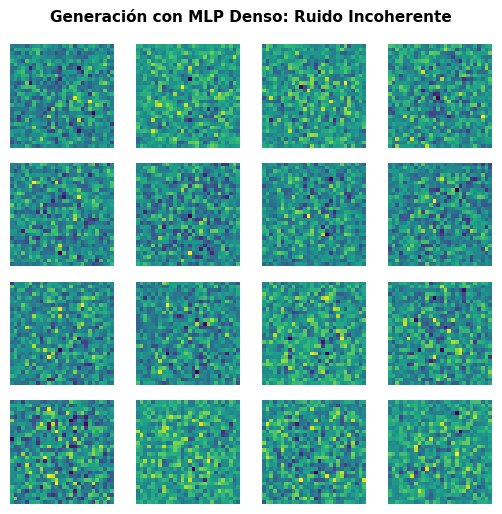

In [24]:
@torch.no_grad()
def plot_full_sampling(
    model,
    n_samples=16,
    title="Generación de Muestras",
    prediction_type="noise",  # Opciones: "noise" o "x_0"
    nrows=4,
    ncols=4,
    add_noise=True,
    device=device,
):
    """
    Función unificada de muestreo reverso para modelos de difusión.
    Soporta modelos que predicen ruido ('noise') o imagen limpia ('x_0').
    """
    model.eval()
    x = torch.randn((n_samples, 1, 28, 28), device=device)

    # 1. Aseguramos dispositivos de los tensores del schedule
    a_bar = alphas_bar.to(device)
    std_noise_all = sqrt_one_minus_alphas_bar_sq.to(device)
    a_step = alphas.to(device)
    b_step = betas.to(device)

    # 2. Coeficientes analíticos para media y varianza posterior
    # Coeficiente c = beta_step / sqrt(1 - alpha_bar^2)
    eps_coef = (1.0 - a_step ** 2) / std_noise_all.clamp(min=1e-12)

    # Varianza posterior sigma^2
    ab2 = a_bar ** 2
    pad_one = torch.ones(1, device=device, dtype=ab2.dtype)
    ab2_prev = torch.cat([pad_one, ab2[:-1]])

    sigma2 = ((1.0 - ab2_prev) / (1.0 - ab2).clamp(min=1e-12)) * (b_step ** 2)
    sigma = torch.sqrt(sigma2.clamp(min=0.0))

    # 3. Bucle inverso de desruido (L -> 1)
    for step in tqdm(range(L, 0, -1), desc=f"Muestreando ({model.__class__.__name__})", leave=False):
        i = torch.full((n_samples,), step, device=device, dtype=torch.long)
        out = model(x, i)

        # Derivación de eps_pred según el tipo de predicción del modelo
        if prediction_type == "noise":
            eps_pred = out
        elif prediction_type == "x_0":
            # Si out es pred_x0, despejamos el ruido implícito: eps = (x - a_bar * x_0) / std
            eps_pred = (x - a_bar[step] * out) / std_noise_all[step].clamp(min=1e-12)
        else:
            raise ValueError(f"Tipo de predicción no válido: {prediction_type}. Usa 'noise' o 'x_0'.")

        # Media condicional
        mean = (x - eps_coef[step] * eps_pred) / a_step[step]

        # Inyección de ruido estocástico
        if step > 1 and add_noise:
            x = mean + sigma[step] * torch.randn_like(x)
        else:
            x = mean

    # 4. Visualización en cuadrícula
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.3, nrows * 1.3))
    grid = min_max_to_01(x).cpu()

    for ax, im in zip(axes.flat, grid):
        ax.imshow(im[0].numpy(), cmap=CMAP)
        ax.axis("off")

    plt.suptitle(title, fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()

plot_full_sampling(
    model=model_MLP,
    n_samples=16,
    title="Generación con MLP Denso: Ruido Incoherente",
    prediction_type="noise"
)

#### Arquitectura: U-Net para Predicción de Ruido

Tras observar el colapso del MLP denso, se hace necesario un cambio de arquitectura: la **U-Net** (estándar en modelos de difusión como DDPM).

El problema fundamental del **MLP** es que aplana la imagen en un vector unidimensional y pierde por completo la noción espacial: **no sabe qué píxeles son vecinos de cuáles**, tratando cada punto de forma aislada e impidiéndole reconstruir trazos o bordes continuos.

Para solucionar esto se utiliza una **U-Net**: una arquitectura basada en capas convolucionales que **sí preserva la estructura 2D de la imagen** y entiende la relación entre píxeles vecinos, combinando visión global y detalle fino para poder reducir el ruido de la imagen con precisión.

In [25]:
class ResBlock(nn.Module):
    def __init__(self, cin, cout, tdim):
        super().__init__()
        self.n1 = nn.GroupNorm(8, cin)
        self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
        self.t = nn.Linear(tdim, cout)
        self.n2 = nn.GroupNorm(8, cout)
        self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
        self.sk = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()

    def forward(self, x, t):
        h = self.c1(F.silu(self.n1(x)))
        h = h + self.t(t)[:, :, None, None]
        h = self.c2(F.silu(self.n2(h)))
        return h + self.sk(x)


class UNetNoiseDiffusionModel(nn.Module):
    def __init__(self, ch=64, time_dim=128, tdim=256, data_sq=0.9):
        super().__init__()
        self.time_dim = time_dim
        self.t_mlp = nn.Sequential(
            nn.Linear(time_dim, tdim),
            nn.SiLU(),
            nn.Linear(tdim, tdim)
        )

        self.inp = nn.Conv2d(1, ch, 3, padding=1)
        self.enc1 = ResBlock(ch, ch, tdim)
        self.down1 = nn.Conv2d(ch, ch, 3, stride=2, padding=1)
        self.enc2 = ResBlock(ch, 2 * ch, tdim)
        self.down2 = nn.Conv2d(2 * ch, 2 * ch, 3, stride=2, padding=1)
        self.mid1 = ResBlock(2 * ch, 4 * ch, tdim)
        self.mid2 = ResBlock(4 * ch, 2 * ch, tdim)
        self.dec2 = ResBlock(2 * ch + 2 * ch, 2 * ch, tdim)
        self.dec1 = ResBlock(2 * ch + ch, ch, tdim)

        self.out_norm = nn.GroupNorm(8, ch)
        self.out = nn.Conv2d(ch, 1, 3, padding=1)
        nn.init.zeros_(self.out.weight)
        nn.init.zeros_(self.out.bias)

        # Skip analítico según EDM / Karras
        std = sqrt_one_minus_alphas_bar_sq.detach().clone().float()
        ab = alphas_bar.detach().clone().float()
        self.register_buffer("c_skip", std / (std**2 + (ab**2) * data_sq).clamp(min=1e-8))

    def forward(self, x, i):
        t = self.t_mlp(get_sinusoidal_embedding(i, self.time_dim))
        h = self.inp(x)
        s1 = self.enc1(h, t)
        s2 = self.enc2(self.down1(s1), t)
        m = self.mid2(self.mid1(self.down2(s2), t), t)
        u2 = F.interpolate(m, scale_factor=2, mode="nearest")
        u2 = self.dec2(torch.cat([u2, s2], dim=1), t)
        u1 = F.interpolate(u2, scale_factor=2, mode="nearest")
        u1 = self.dec1(torch.cat([u1, s1], dim=1), t)
        corr = self.out(F.silu(self.out_norm(u1)))
        return self.c_skip[i].view(-1, 1, 1, 1) * x + corr

In [26]:
EPOCHS = 15
MAX_LR = 2e-4

model_UNet = UNetNoiseDiffusionModel()
opt_UNet = optim.AdamW(model_UNet.parameters(), lr=MAX_LR, weight_decay=0.0)
sched_UNet = optim.lr_scheduler.OneCycleLR(
    opt_UNet, max_lr=MAX_LR,
    total_steps=EPOCHS * len(dataloader),
    pct_start=0.02, anneal_strategy="cos",
)

model_UNet, history_UNet = train_or_load_model(
    model=model_UNet,
    dataloader=dataloader,
    optimizer=opt_UNet,
    loss_fn=compute_ddpm_noise_loss_sampled,
    file_name="model_eps_UNet.pth",   # nombre nuevo
    epochs=EPOCHS,
    train=False,                          # True para entrenar
    device=device,
    scheduler=sched_UNet,
    grad_clip=1.0,
    ema_decay=0.999,
)

-> Pesos e historial cargados correctamente desde: '/content/drive/MyDrive/modelos_difusion/model_eps_UNet.pth'.


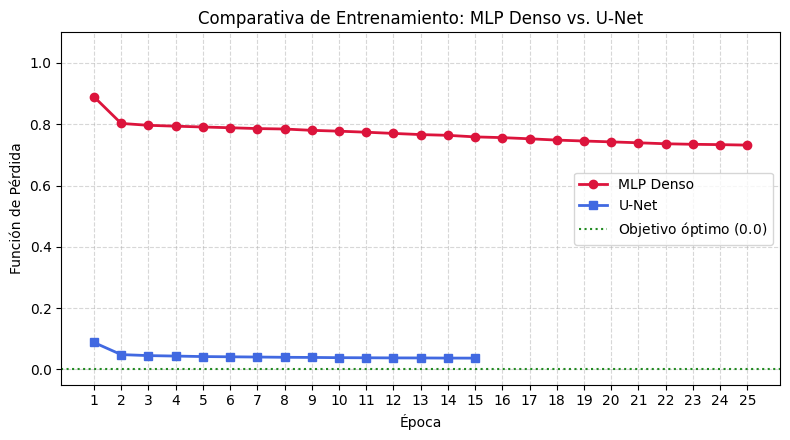

In [27]:
plt.figure(figsize=(8, 4.5))

epochs_mlp = range(1, len(history_MLP) + 1)
epochs_unet = range(1, len(history_UNet) + 1)
max_epochs = max(len(history_MLP), len(history_UNet))
xticks_range = list(range(1, max_epochs + 1))

plt.plot(epochs_mlp, history_MLP, marker="o", color="crimson", linewidth=2, label="MLP Denso")
plt.plot(epochs_unet, history_UNet, marker="s", color="royalblue", linewidth=2, label="U-Net")

plt.axhline(0.0, color="forestgreen", linestyle=":", linewidth=1.5, label="Objetivo óptimo ($0.0$)")

# Formato y límites
plt.ylim(-0.05, 1.1)
plt.title("Comparativa de Entrenamiento: MLP Denso vs. U-Net")
plt.xlabel("Época")
plt.ylabel("Función de Pérdida")
plt.xticks(xticks_range)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="center right")

plt.tight_layout()
plt.show()

Como se puede ver, la arquitectura U-Net es mucho más eficiente a la hora de aprender los valores del ruido, como era de esperar. Veamos que, efectivamente, ha aprendido a reconstruir las imágenes.

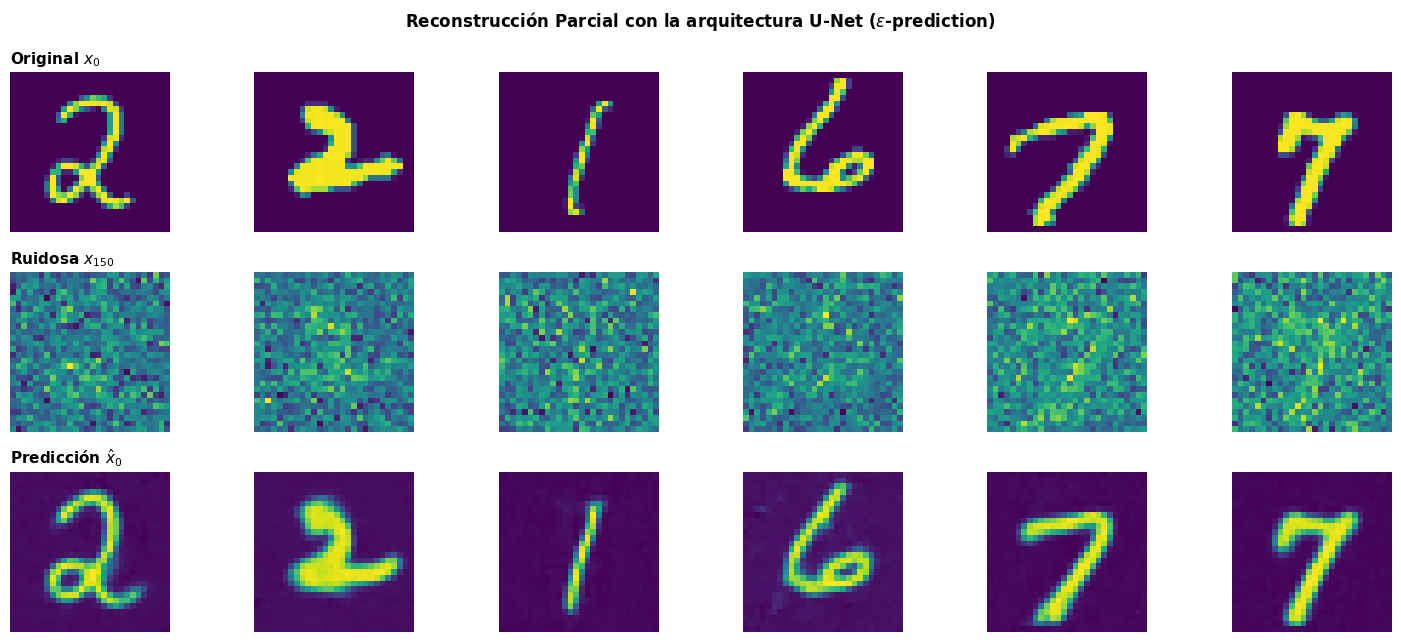

In [28]:
plot_one_step_reconstruction(model_UNet, dataloader, step=L // 2, n=6, title=r"Reconstrucción Parcial con la arquitectura U-Net ($\epsilon$-prediction)", prediction_type="noise")

Muestreando (UNetNoiseDiffusionModel):   0%|          | 0/300 [00:00<?, ?it/s]

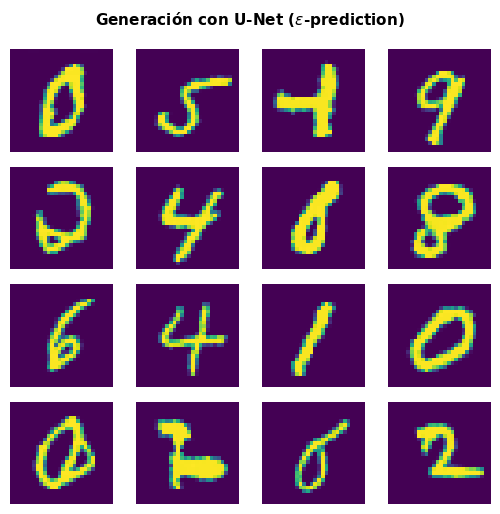

In [29]:
plot_full_sampling(
    model=model_UNet,
    n_samples=16,
    title=r"Generación con U-Net ($\epsilon$-prediction)",
    prediction_type="noise"
)

In [30]:
@torch.no_grad()
def run_model_trajectory(model, L, get_mean_fn, sigmas, alphas_bar, sqrt_one_minus_alphas_bar_sq,
                         predicts_type="eps", shape=(1, 1, 28, 28), device="cuda"):
    model.eval()
    sigmas = sigmas.to(device)
    alphas_bar = alphas_bar.to(device)
    sqrt_one_minus = sqrt_one_minus_alphas_bar_sq.to(device)

    # 1. Empezamos en puro ruido gaussiano en t = L
    current_x = torch.randn(shape, device=device)

    trajectory = {}
    trajectory[L] = current_x.detach()

    # 2. Deshacemos el ruido paso a paso: L -> 1
    for i_val in range(L, 0, -1):
        step_tensor = torch.tensor([i_val], device=device, dtype=torch.long)
        pred = model(current_x, step_tensor)

        # Obtenemos la estimación de x_0 según el modelo
        if predicts_type == "x_0":
            x_0_pred = pred
        elif predicts_type == "eps":
            # x_0 = (x_i - sqrt(1 - a_bar^2) * eps) / a_bar
            x_0_pred = (current_x - sqrt_one_minus[i_val] * pred) / alphas_bar[i_val]
        else:
            raise ValueError(f"predicts_type desconocido: {predicts_type}. Usa 'eps' o 'x_0'.")

        # Usamos tu misma función de media analítica del notebook
        mean = get_mean_fn(x_0_pred, current_x, i_val)

        if i_val > 1:
            noise = torch.randn_like(current_x)
            current_x = mean + sigmas[i_val] * noise
        else:
            current_x = mean

        trajectory[i_val - 1] = current_x.detach()

    return trajectory

In [31]:
# 1. Asegurar coeficientes en el dispositivo correcto
alphas = alphas.to(device)
alphas_bar = alphas_bar.to(device)
betas = betas.to(device)

# Coeficiente alpha_bar desplazado un paso: alpha_bar_{i-1} (con alpha_bar_0 = 1.0)
alphas_bar_prev = torch.cat([torch.tensor([1.0], device=device), alphas_bar[:-1]])

# Varianza posterior analítica sigma_i
sigmas = (betas**2 * (1.0 - alphas_bar_prev**2)) / (1.0 - alphas_bar**2)
sigmas[0] = 0.0
sigmas = torch.sqrt(torch.clamp(sigmas, min=0.0))

# 2. Definición de get_mean_fn
def get_mean_fn(x_0, x_i, i_val):
    """
    Calcula la media del paso reverso p(x_{i-1} | x_i, x_0).
    """
    a_bar_prev = alphas_bar_prev[i_val]
    a_bar = alphas_bar[i_val]
    b_sq = betas[i_val] ** 2
    a = alphas[i_val]
    denom = 1.0 - a_bar ** 2

    # Ponderaciones analíticas
    c_x0 = (a_bar_prev * b_sq) / denom
    c_xi = (a * (1.0 - a_bar_prev ** 2)) / denom

    return c_x0 * x_0 + c_xi * x_i

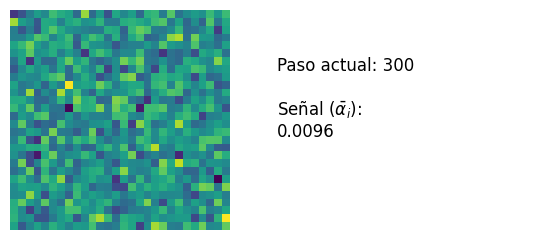

In [32]:
# 1. Generar la trayectoria con la U-Net de ruido
traj_gen = run_model_trajectory(
    model=model_UNet,
    L=L,
    get_mean_fn=get_mean_fn,
    sigmas=sigmas,
    alphas_bar=alphas_bar,
    sqrt_one_minus_alphas_bar_sq=sqrt_one_minus_alphas_bar_sq,
    predicts_type="eps",
    shape=(1, 1, 28, 28),
    device=device
)

# 3. Visualizar el GIF
create_process_gif(
    trajectory=traj_gen,
    steps_sequence=pasos_gif_bwd,
    alphas_bar=alphas_bar,
    duration=60,
    pause_first_ms=1200,   # Pausa en el ruido inicial
    pause_last_ms=2500      # Pausa en el dígito generado final
)

Como se puede ver, ahora sí sinteciza imágenes coherentes. Veamos cómo es la función de pérdida en cada paso.

<>:39: SyntaxWarning: invalid escape sequence '\e'
<>:39: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_47118/2904871295.py:39: SyntaxWarning: invalid escape sequence '\e'
  plot_loss_per_timestep(model_UNet, x_sample, step_stride=2, label="U-Net ($\epsilon$-prediction)")


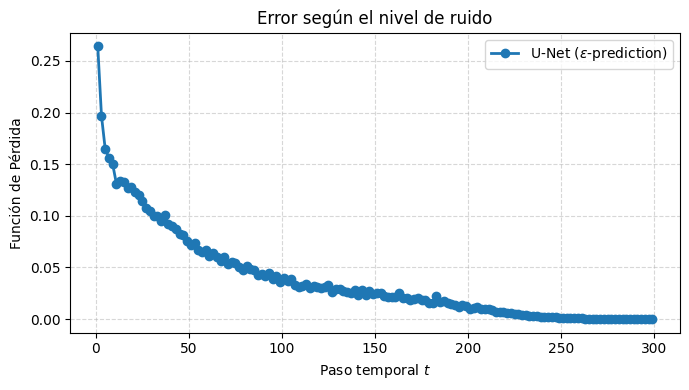

In [33]:
@torch.no_grad()
def plot_loss_per_timestep(model, x_0, step_stride=10, label="Modelo"):
    """
    Calcula y grafica el MSE en función del paso temporal t usando un lote fijo de imágenes x_0.
    """
    model.eval()
    x_0 = x_0.to(device)
    timesteps = list(range(1, L + 1, step_stride))
    losses = []

    for t in timesteps:
        # 1. Proceso forward en el paso t
        noise = torch.randn_like(x_0)
        a_bar = alphas_bar[t]
        x_t = a_bar * x_0 + torch.sqrt(1.0 - a_bar**2) * noise

        # 2. Predicción del modelo y cálculo del MSE
        t_batch = torch.full((x_0.shape[0],), t, device=device, dtype=torch.long)
        pred_noise = model(x_t, t_batch)
        loss = torch.mean((noise - pred_noise) ** 2)
        losses.append(loss.item())

    # 3. Gráfica
    plt.figure(figsize=(7, 4))
    plt.plot(timesteps, losses, marker="o", linewidth=2, label=label)

    plt.xlabel("Paso temporal $t$")
    plt.ylabel("Función de Pérdida")
    plt.title("Error según el nivel de ruido")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Tomamos un lote de imágenes de prueba
x_sample, _ = next(iter(dataloader))

# Graficamos el error del modelo
plot_loss_per_timestep(model_UNet, x_sample, step_stride=2, label="U-Net ($\epsilon$-prediction)")

Como se puede ver, los valores de la función de pérdida difieren mucho en función de la etapa:
- Para etapas cercanas a $L=300$, se predice sin ningún progrema el valor del ruido.
- Para etapas cercanas a $L=0$, el error de predicción es bastante mayor.


## 3. $x_0$ Prediction

En lugar de predecir el ruido $\epsilon$ que se inyectó en la imagen, otra alternativa muy utilizada en modelos de difusión consiste en entrenar a la red neuronal para que prediga directamente la imagen limpia original $x_0$.

A través de la siguiente igualdad, si la red predice la estimación de la imagen limpia $x_\phi(x_i, i) \approx x_0$, podemos despejar la estimación del ruido implícito y así estaríamos en el caso anterior.
$$x_i = \bar{\alpha}_i x_0 + \sqrt{1 - \bar{\alpha}_i^2} \, \epsilon$$

La función de pérdida para entrenar el modelo en la predicción directa de $x_0$ bajo una estimación de Monte Carlo es simplemente el Error Cuadrático Medio (MSE) directo entre la predicción y el dato real original limpio:

$$\mathcal{L}_{x_0}(\phi) = \mathbb{E}_{i, x_0, \epsilon} \left[ w(i)\ \|x_\phi(x_i, i) - x_0\|_2^2 \right]$$

donde $w(i)$ es una función de peso. Al igual que en el caso anterior, puesto que la imagen original predicha debe ser la misma en todos los pasos, se demuestra que puede eliminarse dando lugar al mismo resultado teórico, luego:
$$\mathcal{L}_{x_0}(\phi) = \mathbb{E}_{i, x_0, \epsilon}
\left[\ \|x_\phi(x_i, i) - x_0\|_2^2 \right]$$

A continuación, definimos la función de pérdida y la arquitectura correspondiente.

In [34]:
def compute_ddpm_x0_loss_sampled(model, x_0):
    """
    Calcula la pérdida para el modelo que predice directamente x_0.
    Se muestrea un paso temporal i aleatorio uniforme en [1, L].
    """
    batch_size = x_0.shape[0]

    # 1. Muestreamos pasos aleatorios uniformes en {1, ..., L}
    i_samples = torch.randint(1, L + 1, (batch_size,), device=device).long()

    # 2. Generamos el ruido e inyectamos para obtener x_i
    noise = torch.randn_like(x_0)
    x_i, _ = q_sample(x_0, i_samples, eps=noise)

    # 3. Predicción directa de x_0 por parte de la red
    pred_x0 = model(x_i, i_samples)

    # 4. Pérdida de reconstrucción directa sobre la imagen original
    loss = F.mse_loss(pred_x0, x_0)

    return loss

#### Arquitectura U-Net para Predicción de $x_0$

La arquitectura será idéntica a la que predijo el ruido, pero conceptualmente su capa de salida proyectará la estimación del dígito limpio original $x_0$.


In [35]:
class UNetX0DiffusionModel(UNetNoiseDiffusionModel):
    def __init__(self, ch=64, time_dim=128, tdim=256, data_sq=0.9):
        super().__init__(ch=ch, time_dim=time_dim, tdim=tdim, data_sq=data_sq)
        # Sobrescribimos el skip analytic de la clase padre si es necesario para adaptarlo a x_0,
        # pero mantenemos la estructura de la U-Net idéntica. El forward base devuelve:
        # c_skip * x + corr. Para x_0 simplemente dejamos que la red aprenda la identidad directamente.

    def forward(self, x, i):
        # Redefinimos un forward limpio que no aplique skip-connections analíticas EDM de ruido
        # para dejar que estime libremente la imagen x_0
        t = self.t_mlp(get_sinusoidal_embedding(i, self.time_dim))
        h = self.inp(x)
        s1 = self.enc1(h, t)
        s2 = self.enc2(self.down1(s1), t)
        m = self.mid2(self.mid1(self.down2(s2), t), t)
        u2 = F.interpolate(m, scale_factor=2, mode="nearest")
        u2 = self.dec2(torch.cat([u2, s2], dim=1), t)
        u1 = F.interpolate(u2, scale_factor=2, mode="nearest")
        u1 = self.dec1(torch.cat([u1, s1], dim=1), t)
        out_img = self.out(F.silu(self.out_norm(u1)))
        return out_img

In [36]:
EPOCHS = 15
MAX_LR = 2e-4

model_UNet_x0 = UNetX0DiffusionModel()
opt_UNet_x0 = optim.AdamW(model_UNet_x0.parameters(), lr=MAX_LR, weight_decay=0.0)
sched_UNet_x0 = optim.lr_scheduler.OneCycleLR(
    opt_UNet_x0, max_lr=MAX_LR,
    total_steps=EPOCHS * len(dataloader),
    pct_start=0.02, anneal_strategy="cos",
)

model_UNet_x0, history_UNet_x0 = train_or_load_model(
    model=model_UNet_x0,
    dataloader=dataloader,
    optimizer=opt_UNet_x0,
    loss_fn=compute_ddpm_x0_loss_sampled,
    file_name="model_x0_UNet.pth",
    epochs=EPOCHS,
    train=False,  # Cambiar a False para cargar de drive si ya existe
    device=device,
    scheduler=sched_UNet_x0,
    grad_clip=1.0,
    ema_decay=0.999,
)

-> Pesos e historial cargados correctamente desde: '/content/drive/MyDrive/modelos_difusion/model_x0_UNet.pth'.


Veamos ahora cómo son las imágenes que se generan.

Muestreando (UNetX0DiffusionModel):   0%|          | 0/300 [00:00<?, ?it/s]

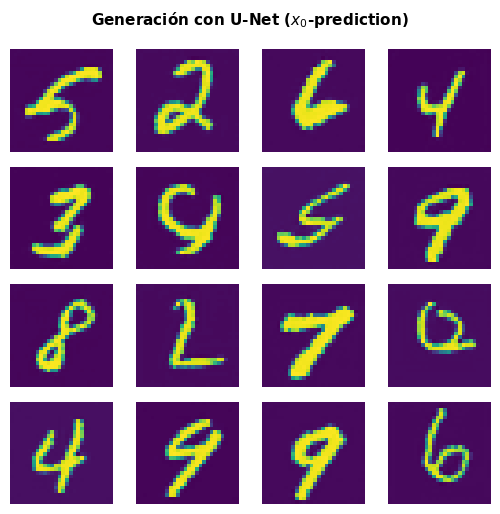

In [37]:
plot_full_sampling(
    model=model_UNet_x0,
    n_samples=16,
    title="Generación con U-Net ($x_0$-prediction)",
    prediction_type="x_0"
)

Procedemos a evaluar visualmente la calidad de la reconstrucción directa en un solo paso intermedio ($i = L/2$) y a analizar cómo varía el error de estimación de $x_0$ a lo largo de todos los pasos temporales de la difusión.

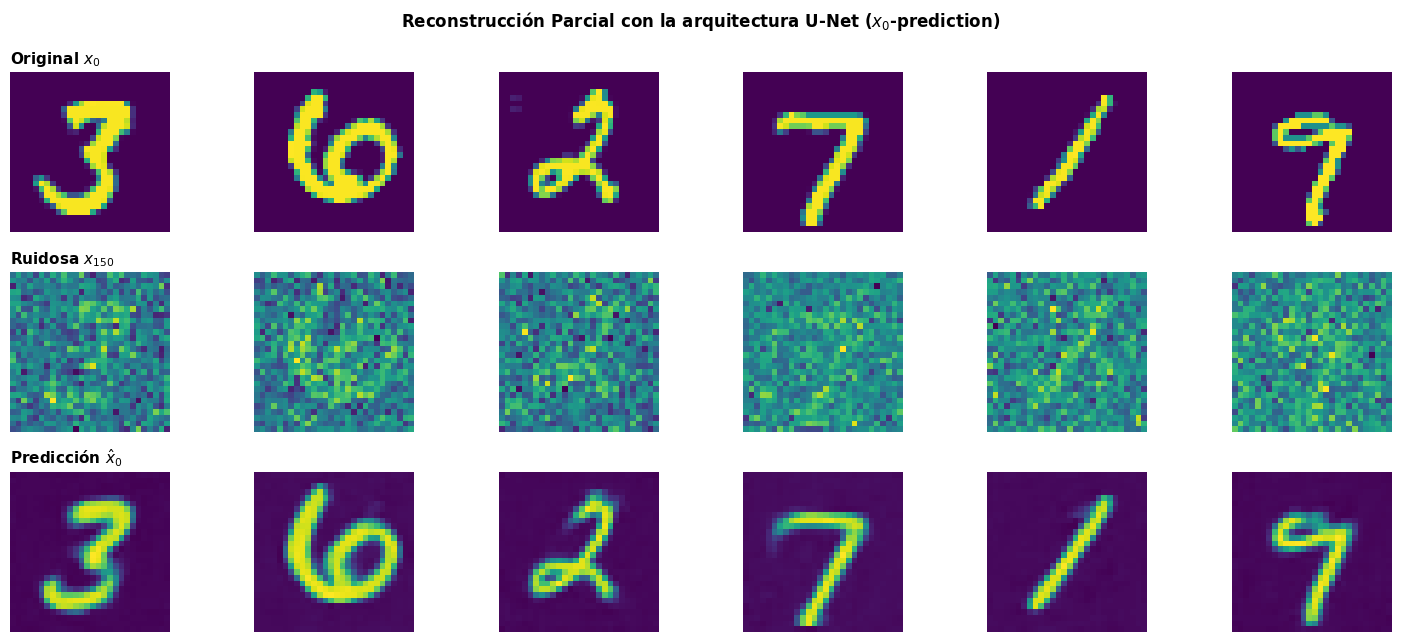

In [38]:
plot_one_step_reconstruction(model_UNet_x0, dataloader, step=L // 2, n=6, title="Reconstrucción Parcial con la arquitectura U-Net ($x_0$-prediction)", prediction_type="x_0")

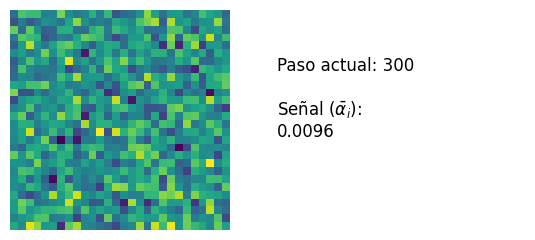

In [39]:
traj_gen_x0 = run_model_trajectory(
    model=model_UNet_x0,
    L=L,
    get_mean_fn=get_mean_fn,
    sigmas=sigmas,
    alphas_bar=alphas_bar,
    sqrt_one_minus_alphas_bar_sq=sqrt_one_minus_alphas_bar_sq,
    predicts_type="x_0",
    shape=(1, 1, 28, 28),
    device=device
)

# 3. Visualizar el GIF
create_process_gif(
    trajectory=traj_gen_x0,
    steps_sequence=pasos_gif_bwd,
    alphas_bar=alphas_bar,
    duration=60,
    pause_first_ms=1200,
    pause_last_ms=2500
)

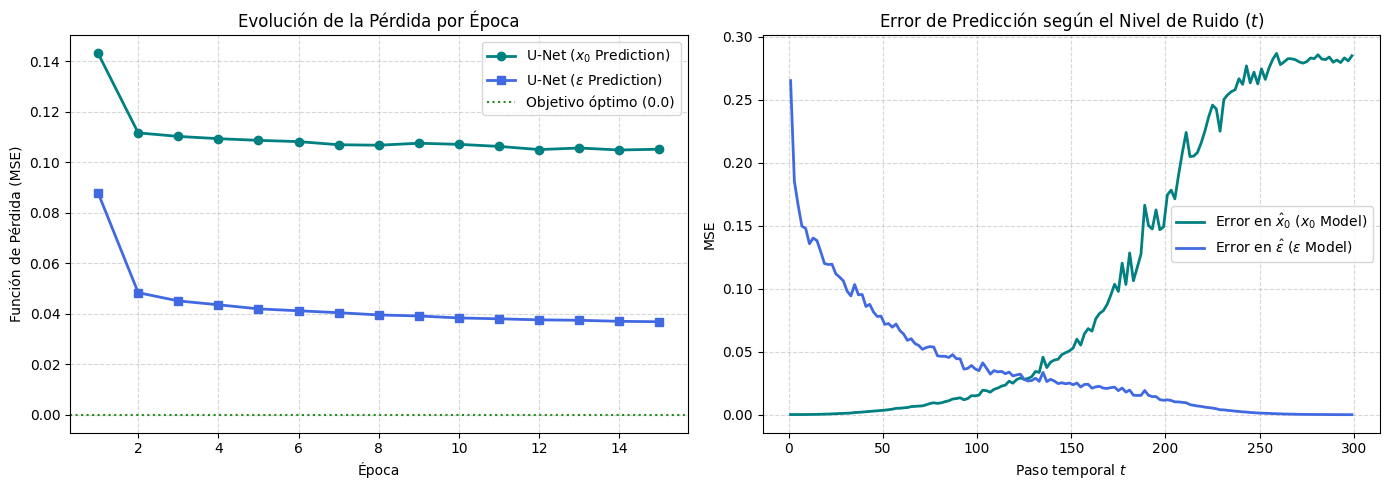

In [40]:
# 1. Comparativa de curvas de entrenamiento
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
epochs_range = range(1, len(history_UNet_x0) + 1)
plt.plot(epochs_range, history_UNet_x0, marker="o", color="teal", linewidth=2, label="U-Net ($x_0$ Prediction)")
plt.plot(epochs_range, history_UNet[:len(history_UNet_x0)], marker="s", color="royalblue", linewidth=2, label="U-Net ($\\epsilon$ Prediction)")
plt.axhline(0.0, color="forestgreen", linestyle=":", linewidth=1.5, label="Objetivo óptimo (0.0)")
plt.title("Evolución de la Pérdida por Época")
plt.xlabel("Época")
plt.ylabel("Función de Pérdida (MSE)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

# 2. Comparativa del error de reconstrucción por paso temporal (t)
plt.subplot(1, 2, 2)
model_UNet_x0.eval()
model_UNet.eval()

timesteps = list(range(1, L + 1, 2))
losses_x0 = []
losses_eps = []
x_test = x_sample.to(device)

with torch.no_grad():
    for t in timesteps:
        noise = torch.randn_like(x_test)
        a_bar = alphas_bar[t]
        x_t = a_bar * x_test + torch.sqrt(1.0 - a_bar**2) * noise
        t_batch = torch.full((x_test.shape[0],), t, device=device, dtype=torch.long)

        # Error para el modelo x0 (calculado en el espacio de la imagen limpia x0)
        pred_x0 = model_UNet_x0(x_t, t_batch)
        loss_x0 = F.mse_loss(pred_x0, x_test)
        losses_x0.append(loss_x0.item())

        # Error para el modelo epsilon (calculado en el espacio del ruido)
        pred_eps = model_UNet(x_t, t_batch)
        loss_eps = F.mse_loss(pred_eps, noise)
        losses_eps.append(loss_eps.item())

plt.plot(timesteps, losses_x0, color="teal", linewidth=2, label="Error en $\\hat{x}_0$ ($x_0$ Model)")
plt.plot(timesteps, losses_eps, color="royalblue", linewidth=2, label="Error en $\\hat{\\epsilon}$ ($\\epsilon$ Model)")
plt.title("Error de Predicción según el Nivel de Ruido ($t$)")
plt.xlabel("Paso temporal $t$")
plt.ylabel("MSE")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

## Un DDPM Analíticamente Resoluble: Mezcla de Gaussianas

En un modelo de difusión estándar, la distribución original de los datos $p_{data}$ (como imágenes reales) es intratable analíticamente. Para comprender la mecánica interna del DDPM sin recurrir a redes neuronales, analizaremos un caso particular donde la distribución inicial $x_0$ es una mezcla explícita de dos gaussianas..

Asumimos matemáticamente que $x_0 \sim w_1 \mathcal{N}(m_1, s_1^2) + w_2 \mathcal{N}(m_2, s_2^2)$. Al conocer la expresión analítica de $p(x_0)$, podemos derivar cada paso del proceso hacia adelante y del proceso inverso de forma exacta y en forma cerrada.

El desarrollo matemático de todos los conceptos de este modelo analítico se encuentra [aquí](https://github.com/arturo-olvrs/DDPM-MNIST/blob/main/DDPM_Anal%C3%ADtico.pdf).

Definimos los parámetros de nuestra mezcla como tensores y visualizamos la distribución original de la que queremos aprender.

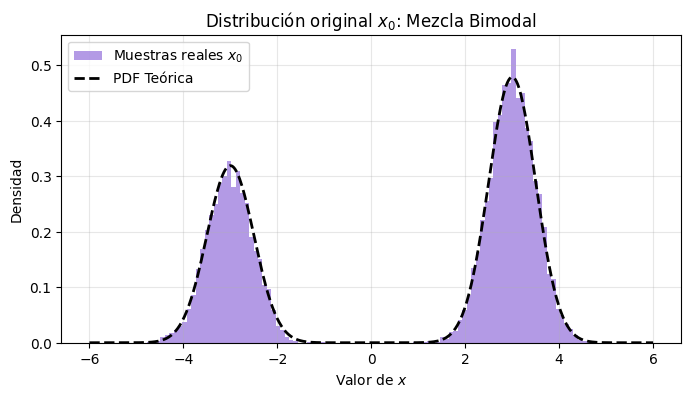

In [47]:
L, beta_0, beta_L, betas, alphas, alphas_bar, sqrt_one_minus_alphas_bar_sq = get_noise_schedule(4, 0.0, 1)

W = torch.tensor([0.4, 0.6])          # Pesos (w_k)
M = torch.tensor([-3, 3.0])         # Medias (m_k)
S = torch.tensor([0.5, 0.5])          # Desviaciones estándar (s_k)
S_sq = S**2

# Generamos muestras reales de la distribución x_0
N_samples = 10000
componentes = torch.multinomial(W, N_samples, replacement=True)
x_0_mezcla = M[componentes] + S[componentes] * torch.randn(N_samples)

# Visualización de la distribución original
plt.figure(figsize=(8, 4))
plt.hist(x_0_mezcla.numpy(), bins=100, density=True, color='mediumpurple', alpha=0.7, label='Muestras reales $x_0$')

# Curva teórica superpuesta mediante operaciones de tensores
x_vals = torch.linspace(-6, 6, 500)
x_reshaped = x_vals.view(-1, 1) # (500, 1) para aprovechar el broadcasting con los parámetros (2,)

pdf_componentes = W * torch.exp(-0.5 * ((x_reshaped - M) / S)**2) / (S * math.sqrt(2 * math.pi))
pdf_teorica = pdf_componentes.sum(dim=1)

plt.plot(x_vals.numpy(), pdf_teorica.numpy(), color='black', lw=2, linestyle='--', label='PDF Teórica')
plt.title('Distribución original $x_0$: Mezcla Bimodal')
plt.xlabel('Valor de $x$')
plt.ylabel('Densidad')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Proceso Hacia Adelante (Forward Process) y Densidad Marginal

Gracias a la estabilidad de la suma de variables normales, sabemos que en cualquier paso $i$, el dato ruidoso $x_i$ condicionado a $x_0$ es:
$$p(x_i|x_0) = \mathcal{N}(x_i; \bar{\alpha}_i x_0, \bar{\beta}_i^2)$$

Dado que $x_0$ es una mezcla de dos gaussianas, aplicando el teorema de la probabilidad total, la densidad marginal $p_i(x_i)$ en CUALQUIER paso sigue siendo exactamente una mezcla de dos gaussianas. Los pesos $w_k$ originales se mantienen, pero las medias y varianzas se van amortiguando y ruidificando conforme avanza el proceso:
$$p_i(x_i) = \sum_{k=1}^2 w_k \mathcal{N}(x_i; \bar{\alpha}_i m_k, \bar{\alpha}_i^2 s_k^2 + \bar{\beta}_i^2)$$

En el paso final $L$, la distribución converge asintóticamente a $\mathcal{N}(0,1)$.

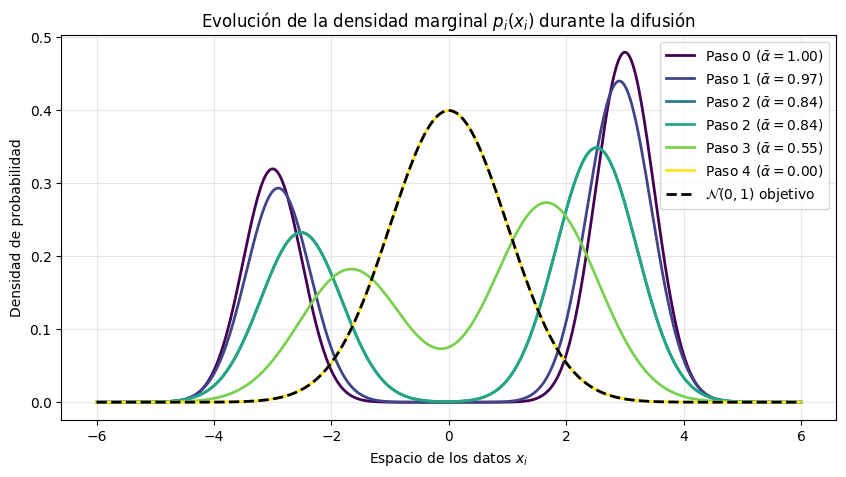

In [48]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

def marginal_pdf_mezcla(x, step):
  """Calcula la densidad marginal teórica p(x_i) en un paso dado vectorizando sobre las componentes."""

  a_bar = alphas_bar[step].item()
  b_bar_sq = sqrt_one_minus_alphas_bar_sq[step].item() ** 2

  # Evolución de los parámetros para todas las componentes (K,)
  mu_i = a_bar * M
  var_i = (a_bar**2) * (S**2) + b_bar_sq

  # Cálculo vectorizado de las densidades
  x_reshaped = x.view(-1, 1)

  pdf_comp = W * torch.exp(-0.5 * ((x_reshaped - mu_i)**2) / var_i) / torch.sqrt(2*math.pi * var_i)


  # La densidad marginal es la suma ponderada de las componentes
  return pdf_comp.sum(dim=1)

plt.figure(figsize=(10, 5))
steps_to_plot = [int(round(frac * L)) for frac in [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]]

cmap = plt.cm.viridis
colores = cmap(np.linspace(0, 1, len(steps_to_plot)))

for step, color in zip(steps_to_plot, colores):
    pdf_vals = marginal_pdf_mezcla(x_vals, step)
    plt.plot(x_vals.numpy(), pdf_vals.numpy(), color=color, lw=2,
             label=f'Paso {step} ($\\bar{{\\alpha}}={alphas_bar[step].item():.2f}$)')

# Curva Normal estándar N(0, 1) objetivo
x_np = x_vals.numpy()
plt.plot(x_np, norm.pdf(x_np, loc=0, scale=1),
         color='black', linestyle='--', lw=2, label=r'$\mathcal{N}(0, 1)$ objetivo')

plt.title('Evolución de la densidad marginal $p_i(x_i)$ durante la difusión')
plt.xlabel('Espacio de los datos $x_i$')
plt.ylabel('Densidad de probabilidad')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 3. Proceso Inverso Exacto vs. Aproximación Gaussiana

Por el teorema de Bayes sobre la cadena markoviana:
$$p(x_{i-1}|x_i) = \sum_{k=1}^2 \tilde{w}_k(x_i) \, p(x_{i-1}|x_i, K=k)$$

Donde cada término se resuelve analíticamente:
1. **Pesos a posteriori $\tilde{w}_k(x_i) = P(K=k|x_i)$**:
   $$\tilde{w}_k(x_i) = \frac{w_k \mathcal{N}\left(x_i; \bar{\alpha}_i m_k, \bar{\alpha}_i^2 s_k^2 + \bar{\beta}_i^2\right)}{\sum_{j=1}^2 w_j \mathcal{N}\left(x_i; \bar{\alpha}_i m_j, \bar{\alpha}_i^2 s_j^2 + \bar{\beta}_i^2\right)}$$
2. **Transición condicional por componente**: Al ser $(X, Y) = (x_{i-1}|K=k, x_i|K=k)$ conjuntamente normal, $(X|Y=x_i) \sim \mathcal{N}(\mu_{i-1|i, k}(x_i), \sigma_{i-1|i, k}^2)$ con:
   $$\mu_{i-1|i, k}(x_i) = \bar{\alpha}_{i-1}m_k + \frac{\alpha_i \operatorname{Var}(X)}{\operatorname{Var}(Y)}\left(x_i - \bar{\alpha}_i m_k\right)$$
   $$\sigma_{i-1|i, k}^2 = \operatorname{Var}(X)\left[1 - \frac{\alpha_i^2 \operatorname{Var}(X)}{\operatorname{Var}(Y)}\right]$$
   donde $\operatorname{Var}(X) = \bar{\alpha}_{i-1}^2 s_k^2 + \bar{\beta}_{i-1}^2$ y $\operatorname{Var}(Y) = \bar{\alpha}_i^2 s_k^2 + \bar{\beta}_i^2$.

#### Frontera de Ambigüedad Exacta $x_i^*$
La frontera donde existe máxima ambigüedad ($\tilde{w}_1(x_i^*) = \tilde{w}_2(x_i^*) = 0.5$) surge de igualar las densidades ponderadas. Desarrollando la ecuación cuadrática $A(x_i^*)^2 + Bx_i^* + C = 0$:
* Si $s_1^2 = s_2^2 = s^2$, la ecuación es lineal:
  $$x_i^* = \frac{\bar{\alpha}_i(m_1 + m_2)}{2} - \frac{\bar{\alpha}_i^2 s^2 + \bar{\beta}_i^2}{\bar{\alpha}_i(m_1 - m_2)} \ln\left(\frac{w_1}{w_2}\right)$$
* Si $s_1^2 \neq s_2^2$, $x_i^*$ es la raíz cuadrática que cae entre ambas componentes.

#### Aproximación Unimodal y Promediado de Modas
Al imponer una transición normal $p_\phi(x_{i-1}|x_i) = \mathcal{N}(x_{i-1}; \mu_\phi, \sigma^2)$, la minimización de la divergencia KL conduce a que la media óptima es la esperanza condicional:
$$\mu^*(x_i) = \mathbb{E}[x_{i-1}|x_i] = \sum_{k=1}^2 \tilde{w}_k(x_i)\mu_{i-1|i, k}(x_i)$$
En $x_i^*$, al competir ambos modos ($\tilde{w}_1 \approx \tilde{w}_2 \approx 0.5$), $\mu^*$ colapsa en el promedio aritmético, forzando la masa en el valle intermedio (*mode averaging*).

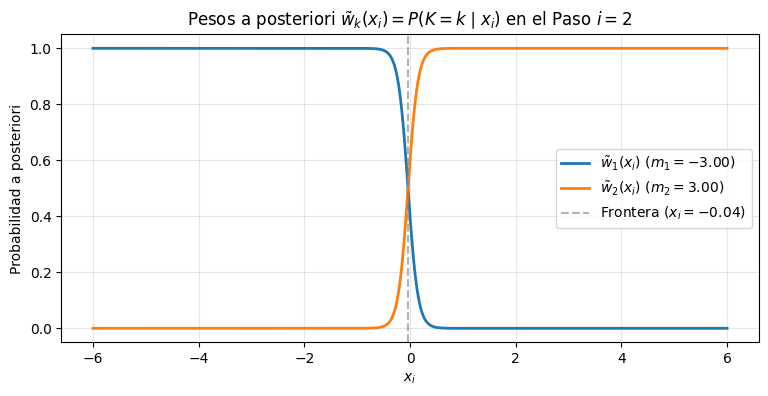

In [49]:
def reverse_posterior_weights(xi, step):
    """Calcula los pesos a posteriori w_tilde_k(x_i) vectorizados para cualquier número de componentes."""
    a_bar_i = alphas_bar[step].item()
    b_bar_i_sq = sqrt_one_minus_alphas_bar_sq[step].item() ** 2

    var_y = (a_bar_i**2) * (S**2) + b_bar_i_sq  # Dimensión: (K,)
    mu_y = a_bar_i * M                          # Dimensión: (K,)

    xi_col = xi.view(-1, 1)                      # Dimensión: (N_puntos, 1)

    # Verosimilitud P(K=k) * p(x_i | K=k)
    densidades = W * torch.exp(-0.5 * ((xi_col - mu_y)**2) / var_y) / torch.sqrt(2 * math.pi * var_y)
    p_xi = densidades.sum(dim=1, keepdim=True)

    # Pesos a posteriori normalizados
    w_tilde = densidades / (p_xi + 1e-12)
    return w_tilde

def reverse_conditional_params(xi, step):
    """Calcula mu_{i-1|i, k}(x_i) y sigma^2_{i-1|i, k} para cada componente."""
    a_i = alphas[step].item()
    a_bar_i = alphas_bar[step].item()
    b_bar_i_sq = sqrt_one_minus_alphas_bar_sq[step].item() ** 2

    a_bar_prev = alphas_bar[step-1].item() if step > 0 else 1.0
    b_bar_prev_sq = sqrt_one_minus_alphas_bar_sq[step-1].item() ** 2 if step > 0 else 0.0

    var_x = (a_bar_prev**2) * (S**2) + b_bar_prev_sq  # Var(x_{i-1} | K=k)
    var_y = (a_bar_i**2) * (S**2) + b_bar_i_sq        # Var(x_i | K=k)

    xi_col = xi.view(-1, 1)

    # Media condicional por componente
    mu_cond = a_bar_prev * M + (a_i * var_x / var_y) * (xi_col - a_bar_i * M)

    # Varianza condicional por componente (constante frente a x_i)
    var_cond = var_x * (1.0 - (a_i**2 * var_x / var_y))

    return mu_cond, var_cond

def calcular_frontera_exacta(step):
    """
    Calcula analíticamente la frontera x_i^* donde w_1(x_i^*) = w_2(x_i^*) = 0.5.
    Válido para varianzas arbitrarias (s_1 != s_2 o s_1 == s_2).
    """
    a_bar_i = alphas_bar[step].item()
    b_bar_i_sq = sqrt_one_minus_alphas_bar_sq[step].item() ** 2

    # Parámetros por componente en el paso i
    m1, m2 = M[0].item(), M[1].item()
    s1_sq, s2_sq = (S[0].item())**2, (S[1].item())**2
    w1, w2 = W[0].item(), W[1].item()

    # Varianzas y medias marginales en el paso i
    v1 = (a_bar_i**2) * s1_sq + b_bar_i_sq
    v2 = (a_bar_i**2) * s2_sq + b_bar_i_sq
    mu1 = a_bar_i * m1
    mu2 = a_bar_i * m2

    # Coeficientes de la ecuación: A*(x*)^2 + B*(x*) + C = 0
    A = (1.0 / v1) - (1.0 / v2)
    B = -2.0 * ((mu1 / v1) - (mu2 / v2))
    C = (mu1**2 / v1) - (mu2**2 / v2) - math.log((w1**2 * v2) / (w2**2 * v1))

    # Si las varianzas marginales son prácticamente iguales (caso lineal)
    if abs(A) < 1e-12:
        return -C / B

    # Caso cuadrático general: A*(x*)^2 + B*(x*) + C = 0
    discriminante = B**2 - 4 * A * C
    if discriminante < 0:
        raise ValueError("No existe solución real para la frontera en este paso.")

    raiz_disc = math.sqrt(discriminante)
    sol1 = (-B + raiz_disc) / (2 * A)
    sol2 = (-B - raiz_disc) / (2 * A)

    # La frontera que separa ambas campanas se encuentra entre las medias mu1 y mu2
    mu_min, mu_max = min(mu1, mu2), max(mu1, mu2)
    if mu_min <= sol1 <= mu_max:
        return sol1
    elif mu_min <= sol2 <= mu_max:
        return sol2
    else:
        # Si por asimetría cae fuera del segmento estricto, seleccionamos la más cercana al punto medio
        punto_medio = 0.5 * (mu1 + mu2)
        return sol1 if abs(sol1 - punto_medio) < abs(sol2 - punto_medio) else sol2

# Visualización de los pesos a posteriori w_tilde(x_i) a lo largo del espacio x_i
plt.figure(figsize=(9, 4))
step = int(L / 2)
w_post_example = reverse_posterior_weights(x_vals, step=step)

# Colores automáticos según la cantidad de componentes en M
cmap = plt.cm.tab10
num_componentes = len(M)

for k in range(num_componentes):
    m_val = M[k].item()
    color = cmap(k)
    plt.plot(
        x_vals.numpy(),
        w_post_example[:, k].numpy(),
        label=rf'$\tilde{{w}}_{k+1}(x_i)$ ($m_{k+1}={m_val:.2f}$)',
        color=color,
        lw=2
    )

# Cálculo exacto de la frontera analítica
frontera = calcular_frontera_exacta(step=step)

# Graficamos la línea en la frontera calculada analíticamente
plt.axvline(
    frontera,
    color='gray',
    linestyle='--',
    alpha=0.6,
    label=f'Frontera ($x_i={frontera:.2f}$)'
)

plt.title(rf'Pesos a posteriori $\tilde{{w}}_k(x_i) = P(K=k \mid x_i)$ en el Paso $i={step}$')
plt.xlabel('$x_i$')
plt.ylabel('Probabilidad a posteriori')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 3.2. Aproximación Gaussiana Unimodal $p_\phi(x_{i-1}|x_i)$ vía Divergencia KL

Dado que en los DDPM estándar las transiciones inversas se parametrizan como gaussianas simples $p_\phi(x_{i-1}|x_i) = \mathcal{N}\left(x_{i-1}; \mu_\phi(x_i, i), \sigma^2(i)\right)$, buscamos la media óptima $\mu^*(x_i)$ que minimiza la divergencia KL:
$$\mu^*(x_i) = \arg\min_{\mu_\phi} \mathcal{D}_{KL}\left(p(\cdot|x_i) \,\|\, p_\phi(\cdot|x_i)\right) = \arg\min_{\mu_\phi} \mathbb{E}\left[(x_{i-1} - \mu_\phi)^2 \mid x_i\right]$$

Al ser una función cuadrática convexa, derivando e igualando a cero se obtiene que la media óptima coincide exactamente con la **esperanza condicional verdadera**:
$$\mu^*(x_i) = \mathbb{E}[x_{i-1} \mid x_i] = \sum_{k=1}^2 \tilde{w}_k(x_i) \, \mu_{i-1|i, k}(x_i)$$

#### El Fenómeno del Promediado de Modas (*Mode Averaging*)
* Si $x_i$ fue generado por $K=1$, entonces $\tilde{w}_1(x_i) \approx 1$ y $\mu^*(x_i) \approx \mu_{i-1|i, 1}(x_i)$ (certeza hacia la rama izquierda).
* Si $x_i$ fue generado por $K=2$, entonces $\tilde{w}_2(x_i) \approx 1$ y $\mu^*(x_i) \approx \mu_{i-1|i, 2}(x_i)$ (certeza hacia la rama derecha).
* **Zona de ambigüedad:** Ambos pesos compiten ($\tilde{w}_1 \approx \tilde{w}_2 \approx 0.5$). La media óptima colapsa en el promedio aritmético de ambas campanas.
Si la transición aproxima la mezcla con una normal centrada en cero, generará masa de probabilidad en el **valle intermedio**, una región de densidad prácticamente nula en los datos reales.

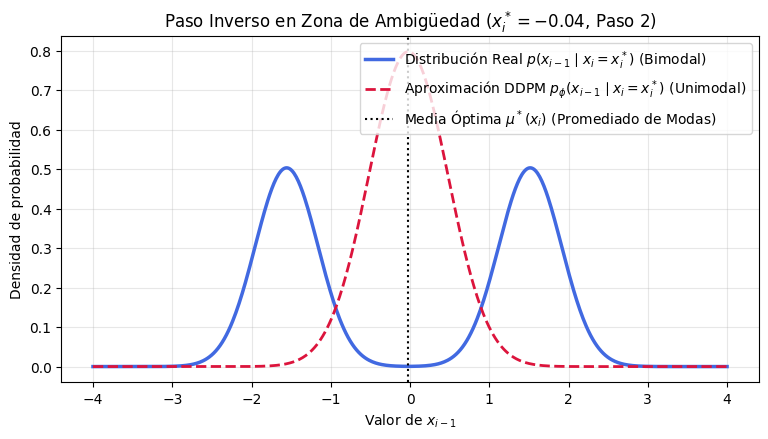

In [50]:
# Evaluamos un paso con ruido moderado (ej. i = 180) para observar la densidad de x_{i-1} dado x_i = 0
step_eval = step
xi_ambiguo = torch.tensor(frontera) # Observación en el centro de ambigüedad

# Parámetros condicionales en x_i = 0
mu_cond_amb, var_cond_amb = reverse_conditional_params(xi_ambiguo, step_eval)
w_tilde_amb = reverse_posterior_weights(xi_ambiguo, step_eval)

# Media óptima que predeciría el DDPM estándar (esperanza condicional)
mu_optimo = (w_tilde_amb * mu_cond_amb).sum().item()

# Varianza fijada estándar en DDPM: beta_i^2 o sigma^2 condicional
sigma_sq_ddpm = betas[step_eval].item()**2

# Evaluamos la densidad de x_{i-1} en una rejilla
u_vals = torch.linspace(-4, 4, 600)
u_col = u_vals.view(-1, 1)

# 1. Densidad real p(x_{i-1} | x_i=0) -> Mezcla bimodal
pdf_comp_real = w_tilde_amb * torch.exp(-0.5 * ((u_col - mu_cond_amb)**2) / var_cond_amb) / torch.sqrt(2 * math.pi * var_cond_amb)
pdf_real = pdf_comp_real.sum(dim=1)

# 2. Densidad aproximada p_phi(x_{i-1} | x_i=0) -> Gaussiana unimodal centrada en mu*
pdf_ddpm_aprox = torch.exp(-0.5 * ((u_vals - mu_optimo)**2) / sigma_sq_ddpm) / math.sqrt(2 * math.pi * sigma_sq_ddpm)

plt.figure(figsize=(9, 4.5))
plt.plot(u_vals.numpy(), pdf_real.numpy(), color='royalblue', lw=2.5, label=r'Distribución Real $p(x_{i-1} \mid x_i=x_i^*)$ (Bimodal)')
plt.plot(u_vals.numpy(), pdf_ddpm_aprox.numpy(), color='crimson', lw=2, linestyle='--', label=r'Aproximación DDPM $p_\phi(x_{i-1} \mid x_i=x_i^*)$ (Unimodal)')
plt.axvline(mu_optimo, color='black', linestyle=':', label=r'Media Óptima $\mu^*(x_i)$ (Promediado de Modas)')

plt.title(f'Paso Inverso en Zona de Ambigüedad ($x_i^*={frontera:.2f}$, Paso {step_eval})')
plt.xlabel('Valor de $x_{i-1}$')
plt.ylabel('Densidad de probabilidad')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Simulación del Proceso Inverso: Distribución Verdadera $p(x_{i-1} \mid x_i)$ vs. Aproximación Gaussiana Óptima $p_\phi(x_{i-1} \mid x_i)$

A continuación compararemos dos métodos para la trayectoria inversa:
1. **Verdadera $p(x_{i-1} \mid x_i)$**: Muestreo en dos etapas (primero la componente $K \sim \tilde{w}_k(x_i)$, luego $x_{i-1} \sim \mathcal{N}(\mu_{i-1\mid i, K}, \sigma_{i-1\mid i, K}^2)$).
2. **Aproximación Gaussiana Óptima $p_\phi(x_{i-1} \mid x_i)$**: Muestreo desde una única normal centrada en la esperanza condicional $\mu^*(x_i) = \sum_k \tilde{w}_k(x_i) \mu_{i-1\mid i, k}(x_i)$.

Probamos con diferentes números de pasos $L$ (saltos) para verificar teórica y empíricamente cómo al aumentar $L$ ($\beta_i^2 \to 0$), la discrepancia entre ambas desaparece.

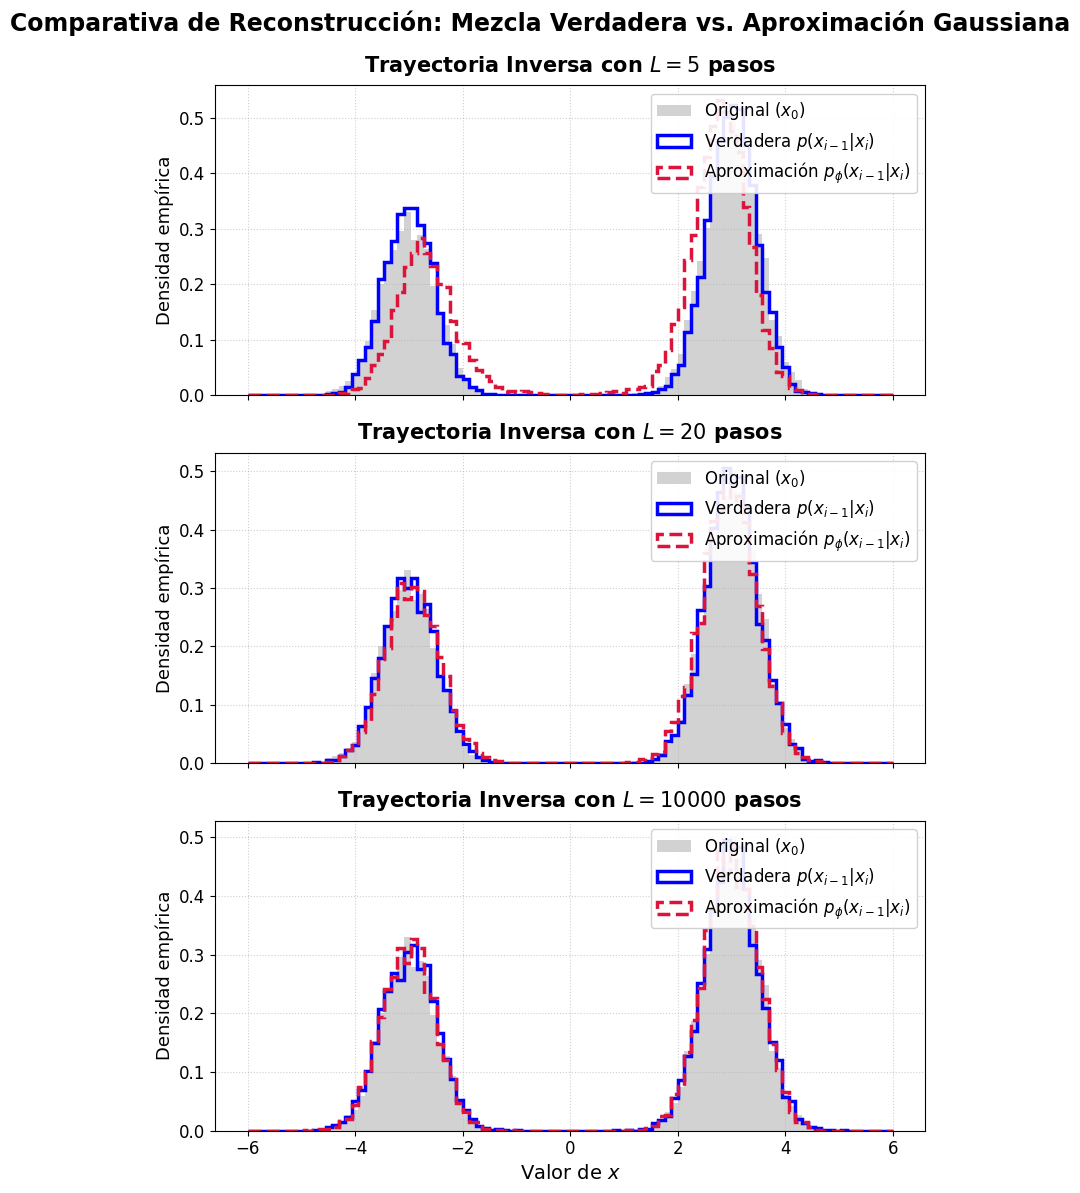

In [51]:
def simulate_diffusion_experiment(L_steps):
    # Noise schedule que asegura que en x_L se destruya la señal (bar_alpha -> 0)
    # Evitamos beta=1.0 exacto para no causar divisiones por cero con alpha=0
    betas = torch.linspace(0.01, 0.99, L_steps + 1)
    alphas = torch.sqrt(torch.clamp(1.0 - betas**2, min=1e-5))
    alphas_bar = torch.cumprod(alphas, dim=0)
    betas_bar_sq = torch.clamp(1.0 - alphas_bar**2, min=1e-5)

    # --- FORWARD PROCESS: Muestras de x_0 llevadas a x_L ---
    x0_real = x_0_mezcla
    eps = torch.randn(N_samples)
    x_L = alphas_bar[L_steps] * x0_real + torch.sqrt(betas_bar_sq[L_steps]) * eps

    x_true = x_L.clone()
    x_approx = x_L.clone()

    # --- REVERSE PROCESS (de L hasta 1) ---
    for i in range(L_steps, 0, -1):
        a_i = alphas[i]
        a_bar_prev = alphas_bar[i - 1]
        a_bar_curr = alphas_bar[i]
        b_bar_sq_prev = betas_bar_sq[i - 1]
        b_bar_sq_curr = betas_bar_sq[i]

        var_X = a_bar_prev**2 * S_sq + b_bar_sq_prev
        var_Y = a_bar_curr**2 * S_sq + b_bar_sq_curr

        mean_Y = a_bar_curr * M
        std_Y = torch.sqrt(var_Y)

        dist_0 = torch.distributions.Normal(mean_Y[0], std_Y[0])
        dist_1 = torch.distributions.Normal(mean_Y[1], std_Y[1])

        # -------------------------------------------------------------
        # A) PROCESO INVERSO EXACTO: p(x_{i-1} | x_i)
        # -------------------------------------------------------------
        log_p0 = torch.log(W[0]) + dist_0.log_prob(x_true)
        log_p1 = torch.log(W[1]) + dist_1.log_prob(x_true)
        w_tilde_1 = 1.0 / (1.0 + torch.exp(torch.clamp(log_p0 - log_p1, -50, 50)))
        K_sampled = torch.bernoulli(w_tilde_1).long()

        mu_k0 = a_bar_prev * M[0] + (a_i * var_X[0] / var_Y[0]) * (x_true - mean_Y[0])
        mu_k1 = a_bar_prev * M[1] + (a_i * var_X[1] / var_Y[1]) * (x_true - mean_Y[1])
        mu_true = torch.where(K_sampled == 0, mu_k0, mu_k1)

        sigma_sq_k = torch.clamp(var_X * (1.0 - (a_i**2 * var_X) / var_Y), min=1e-6)
        sigma_true = torch.sqrt(torch.where(K_sampled == 0, sigma_sq_k[0], sigma_sq_k[1]))

        noise_t = torch.randn_like(x_true) if i > 1 else 0.0
        x_true = mu_true + sigma_true * noise_t

        # -------------------------------------------------------------
        # B) APROXIMACIÓN UNIMODAL: p_\phi(x_{i-1} | x_i)
        # -------------------------------------------------------------
        log_p0_app = torch.log(W[0]) + dist_0.log_prob(x_approx)
        log_p1_app = torch.log(W[1]) + dist_1.log_prob(x_approx)
        w_tilde_1_app = (1.0 / (1.0 + torch.exp(torch.clamp(log_p0_app - log_p1_app, -50, 50)))).clamp(0.0, 1.0)
        w_tilde_0_app = 1.0 - w_tilde_1_app

        mu_k0_app = a_bar_prev * M[0] + (a_i * var_X[0] / var_Y[0]) * (x_approx - mean_Y[0])
        mu_k1_app = a_bar_prev * M[1] + (a_i * var_X[1] / var_Y[1]) * (x_approx - mean_Y[1])

        # Media condicional E[x_{i-1} | x_i]
        mu_star = w_tilde_0_app * mu_k0_app + w_tilde_1_app * mu_k1_app

        sigma_sq_app = torch.clamp((sigma_sq_k[0] + sigma_sq_k[1]) / 2.0, min=1e-6)
        sigma_app = torch.sqrt(sigma_sq_app)

        noise_a = torch.randn_like(x_approx) if i > 1 else 0.0
        x_approx = mu_star + sigma_app * noise_a

    return x0_real, x_true, x_approx

# ==============================================================================
# 3. VISUALIZACIÓN EN FORMATO VERTICAL AMPLIO
# ==============================================================================
steps_to_test = [5, 20, 10000]
bins = np.linspace(-6, 6, 100)

# 3 filas x 1 columna con figsize amplio (12 x 15)
fig, axes = plt.subplots(len(steps_to_test), 1, figsize=(8, 12), sharex=True)

for idx, L in enumerate(steps_to_test):
    x0_real, x_true, x_approx = simulate_diffusion_experiment(L_steps=L)

    ax = axes[idx]
    ax.hist(x0_real.numpy(), bins=bins, density=True, alpha=0.35, color="gray", label=r"Original ($x_0$)")
    ax.hist(x_true.numpy(), bins=bins, density=True, histtype="step", linewidth=2.5, color="blue", label=r"Verdadera $p(x_{i-1}|x_i)$")
    ax.hist(x_approx.numpy(), bins=bins, density=True, histtype="step", linewidth=2.5, color="crimson", linestyle="--", label=r"Aproximación $p_\phi(x_{i-1}|x_i)$")

    ax.set_title(f"Trayectoria Inversa con $L = {L}$ pasos", fontsize=15, fontweight="bold", pad=10)
    ax.set_ylabel("Densidad empírica", fontsize=13)
    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper right", fontsize=12, framealpha=0.9)

axes[-1].set_xlabel("Valor de $x$", fontsize=14)
plt.suptitle("Comparativa de Reconstrucción: Mezcla Verdadera vs. Aproximación Gaussiana", y=0.99, fontsize=17, fontweight="bold")
plt.tight_layout()
plt.show()